# Diabetes Knowledge Graph from Vinmec with Neo4j

This notebook explains the whole `graph_01` project from the very beginning: what problem a Knowledge Graph solves, where the data came from, how ordinary Vietnamese health articles were turned into clean facts, how those facts are stored in the Neo4j database, how we ask questions of them, how we draw them, and how much we can trust them. Every step is explained together with **why** it was done that way and what would go wrong if it were done differently.

The project is four programs that run one after the other. Each one takes the output of the previous one:

```
vinmec.com ──(1) kg/crawl.py──▶ dataset/raw/pages/*.json      1,096 articles as structured text
            ──(2) kg/extract.py ─────────────▶ dataset/processed/*.csv       facts (subject, relation, object)
            ──(3) kg/load.py ──────────▶ Neo4j graph database          nodes + relationships on disk
            ──(4) Cypher / kg/retriever.py / kg/visualize.py ──▶ answers, retrieved facts, figures
```

Why split it into four programs instead of one big script? Because each stage is slow or fragile in a different way. Crawling 1,200 web pages takes about 20 minutes and depends on the website being reachable, so we do it once and save the result. Extraction is where we experiment most (we changed the rules several times after checking the quality), so it must be cheap to re-run without downloading anything again. Loading into Neo4j is a separate step so the database can be wiped and rebuilt from the CSV files at any time. This notebook does not re-implement any of them; it imports their functions and opens up each stage so you can look at the data in between.

| Part | What you will see |
|---|---|
| 1 | What a Knowledge Graph is, built by hand from 7 diabetes facts |
| 2 | The data: how pages were found, why many were rejected, what a saved page looks like |
| 3 | Extraction: vocabulary, section rules, choosing the subject, counting evidence |
| 4 | The resulting graph: what entities and facts we ended up with |
| 5 | Neo4j: why a graph database, how the data is modelled and loaded |
| 6 | Asking questions with Cypher: one-hop, two-hop, symptom checker, paths, evidence |
| 7 | Graph retrieval with `graph_facts()` and why it must be limited |
| 8 | Drawing the graph and finding the most important entities |
| 9 | Checking the quality of the facts |
| 10 | What this graph cannot do |

**Before running:** Neo4j must be running (`docker start neo4j-diabetes`) and loaded (`python kg/load.py`). From Part 5 onwards the cells talk to the database.

In [1]:
import sys, json, csv, re, random
from pathlib import Path
from collections import Counter, defaultdict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "kg"))

RAW = ROOT / "dataset" / "raw"
PROC = ROOT / "dataset" / "processed"
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("project root:", ROOT)

project root: /Users/abc/Documents/study/intelligent-systems/intelligent_system_assignments/graph_01


## 1. What is a Knowledge Graph?

### The problem with text

Vinmec's page about type 2 diabetes says, among many other things:

> *"Những triệu chứng kinh điển của tiểu đường: ăn nhiều, uống nhiều, tiểu nhiều, gầy nhiều… Biến chứng mạn tính: nhìn mờ do biến chứng võng mạc… tê bì dị cảm ở bàn chân (biến chứng thần kinh)…"*

A person reading this understands it immediately. A computer does not. For a program this paragraph is just a long sequence of characters. If you ask it *"which complications of type 2 diabetes affect the eyes?"*, it has nothing to work with except searching for words, and word search is unreliable: the word "mắt" might not appear at all (the text says "võng mạc"), or it might appear in a sentence that says the opposite of what you want. And the answer to a question is usually spread over many articles, written in different ways.

### The idea: store knowledge as small facts

A Knowledge Graph stores knowledge not as sentences but as many small, separate **facts**. Each fact connects exactly two things with a named relationship. It is always written in the same three-part shape: *(the thing the fact is about, the kind of relationship, the other thing)*. This shape is called a **triple**, and its three parts are called **subject**, **relation** and **object**.

The paragraph above becomes facts such as:

| subject | relation | object |
|---|---|---|
| Đái tháo đường type 2 | HAS_SYMPTOM | Khát nhiều |
| Đái tháo đường type 2 | HAS_SYMPTOM | Tiểu nhiều |
| Đái tháo đường type 2 | HAS_COMPLICATION | Bệnh võng mạc |
| Bệnh võng mạc | AFFECTS_ORGAN | Mắt |

Why is this better? Because every fact now has a fixed, predictable form. A program does not need to understand Vietnamese grammar to use it: it only needs to look for facts whose subject is "type 2" and whose relation is "HAS_COMPLICATION". The ambiguity of language has been removed once, at the time the facts were created, instead of every time a question is asked.

### Why it is called a graph

If you draw every thing as a dot and every fact as an arrow between two dots, you get a network: a **graph**. The things are the **nodes** (also called entities), the facts are the **edges** (also called relationships). Each node also has a **type**, for example `Symptom`, `Drug` or `Complication`, so the program knows what kind of thing it is.

Thinking of it as a network is what makes it powerful, because questions become **walks along the arrows**. To answer "which organs can type 2 diabetes damage?" you start at the dot *type 2*, follow every `HAS_COMPLICATION` arrow to the complications, and from each complication follow its `AFFECTS_ORGAN` arrow to an organ. No single fact contains the answer, but by walking two steps you combine facts into new knowledge. And because you can show exactly which arrows you walked, the answer explains itself. A neural network that predicts an answer cannot do that.

Let us build a tiny version by hand with the NetworkX library, the same way the lecture does, before looking at the real graph with 339 facts.

8 nodes, 7 edges


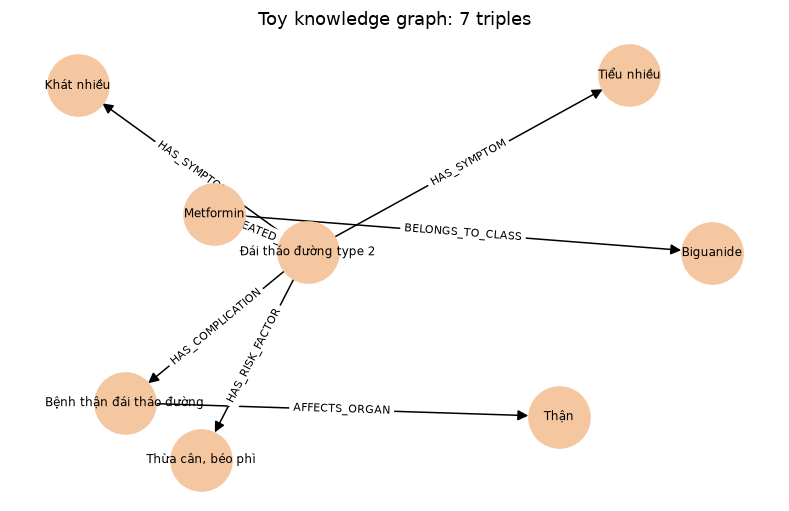

In [2]:
toy = [
    ("Đái tháo đường type 2", "HAS_SYMPTOM",      "Khát nhiều"),
    ("Đái tháo đường type 2", "HAS_SYMPTOM",      "Tiểu nhiều"),
    ("Đái tháo đường type 2", "HAS_RISK_FACTOR",  "Thừa cân, béo phì"),
    ("Đái tháo đường type 2", "HAS_COMPLICATION", "Bệnh thận đái tháo đường"),
    ("Đái tháo đường type 2", "TREATED_BY",       "Metformin"),
    ("Bệnh thận đái tháo đường", "AFFECTS_ORGAN", "Thận"),
    ("Metformin", "BELONGS_TO_CLASS", "Biguanide"),
]
T = nx.DiGraph()
for s, r, o in toy:
    T.add_edge(s, o, relation=r)

print(f"{T.number_of_nodes()} nodes, {T.number_of_edges()} edges")
pos = nx.spring_layout(T, seed=3, k=1.4)
plt.figure(figsize=(9, 5.5))
nx.draw_networkx(T, pos, node_color="#f4c7a1", node_size=1600, font_size=8, arrowsize=14)
nx.draw_networkx_edge_labels(T, pos, nx.get_edge_attributes(T, "relation"), font_size=7)
plt.title("Toy knowledge graph: 7 triples"); plt.axis("off"); plt.show()

### One-hop and two-hop questions on the toy graph

There are two basic kinds of questions you can ask a graph.

A **one-hop** question only looks at the arrows directly attached to one node. "What do we know about Metformin?" means: find the Metformin dot and read every arrow that touches it, both the arrows that leave it (Metformin → Biguanide, its drug class) and the arrows that arrive at it (type 2 → Metformin, "type 2 is treated by Metformin"). The direction of an arrow only says how the fact is phrased; for "what do we know about X" we want both directions.

A **two-hop** question chains two arrows, with a node in the middle that connects them. "Which organ does type 2 damage?" cannot be answered by any single arrow, because the article never says "type 2 damages the kidney" in one fact. It says type 2 can cause *diabetic kidney disease*, and separately we know that diabetic kidney disease affects the *kidney*. The middle node, the complication, is the bridge. This is exactly where a graph is better than a list of sentences: combining facts is just following arrows.

The function below turns arrows back into readable sentences. This is the same idea as the lecture's `graph_facts`, and in Part 7 we use the real version on the real graph.

In [3]:
def toy_facts(G, entity):
    out  = [f"{entity} {d['relation']} {t}." for _, t, d in G.out_edges(entity, data=True)]
    inn  = [f"{s} {d['relation']} {entity}." for s, _, d in G.in_edges(entity, data=True)]
    return out + inn

print("1-hop around Metformin:")
for f in toy_facts(T, "Metformin"): print("  ", f)

print("\n2-hop: organs damaged by type 2")
for _, comp, d1 in T.out_edges("Đái tháo đường type 2", data=True):
    if d1["relation"] != "HAS_COMPLICATION": continue
    for _, organ, d2 in T.out_edges(comp, data=True):
        if d2["relation"] == "AFFECTS_ORGAN":
            print(f"   type 2 → {comp} → {organ}")

1-hop around Metformin:
   Metformin BELONGS_TO_CLASS Biguanide.
   Đái tháo đường type 2 TREATED_BY Metformin.

2-hop: organs damaged by type 2
   type 2 → Bệnh thận đái tháo đường → Thận


The rest of the notebook is the same idea, just much larger. Building a graph by hand from 7 facts is easy. The hard part of the project is getting **correct facts out of 1,096 Vietnamese articles automatically**, without a person reading each one. Parts 2 and 3 explain how that was done and why each decision was made.

## 2. The data: collecting diabetes articles from Vinmec

### 2.1 Why Vinmec

Vinmec is a large Vietnamese hospital group whose website publishes thousands of health articles written or reviewed by its doctors, plus a set of official "disease pages" with a fixed structure (overview, causes, symptoms, risk groups, prevention, diagnosis, treatment). For a diabetes knowledge graph in Vietnamese this is a good source: the language matches, the topic is covered in depth (there are almost a thousand diabetes articles), and the writing is reasonably consistent, which makes automatic extraction possible.

### 2.2 Finding the pages

The obvious way to find diabetes articles would be to use the website's search box. That does not work for a program. Vinmec's search results are produced by JavaScript running inside the browser after the page has loaded. When a program downloads the search page directly, it receives the empty page before the JavaScript has run, so there are no results in it.

Instead the crawler uses the **sitemap**. Large websites publish a sitemap file so that search engines like Google can find every page; it is simply a list of all URLs on the site. Vinmec's sitemap points to about 230 smaller sitemaps. We read the ones for Vietnamese articles (`posts-vi-*.xml`) and Vietnamese disease pages (`diseases-vi-*.xml`), which together list about 222,000 URLs. That is the entire Vietnamese website.

Now we need to pick the diabetes pages out of 222,000 without downloading them all. Every URL ends with a short readable name of the article, called a **slug**. Slugs are written without Vietnamese accents: the article "Tiểu đường tuýp 2: nguyên nhân…" has the slug `tieu-duong-tuyp-2-…`. So we keep a URL if its slug contains a diabetes keyword. The keywords are of two strengths:

- **strong keywords** such as `tieu-duong` and `thao-duong`: if the slug contains one of these, the page is almost certainly about diabetes;
- **weak keywords** such as `insulin`, `hba1c`, `duong-huyet` (blood sugar), `metformin`: the page *might* be about diabetes, but these words also appear in articles about other things (an article about blood sugar in healthy people, or about the hormone insulin in general).

The slug `thao-nhat` is excluded on purpose. *Đái tháo nhạt* (diabetes insipidus) shares the words "đái tháo" with *đái tháo đường* but is a completely different disease of the kidneys and hormones, not of blood sugar.

This leaves **1,197 candidate URLs**. The crawler downloads them politely: the site's `robots.txt` file (where a website says what robots may access) allows these pages, and the crawler waits one second between requests so it does not overload the server.

### 2.3 Why a second filter is needed after downloading

Choosing pages by slug has a hidden problem, and it comes from removing the accents. Vietnamese has many words that are written with the same letters and differ only in their accents. Once the accents are gone, they become identical:

- `tieu-duong` is *tiểu đường* (diabetes), but it is also the start of *tiểu dương vật* (a urology article about a child's penis);
- `dai-duong` is *đái đường* (diabetes), but also *đại dương* (ocean), as in *"cá ngừ đại dương"* (ocean tuna);
- `duong` also appears in *dưỡng ẩm* (moisturising).

These pages passed the slug filter but have nothing to do with diabetes. So after downloading, every page is checked again, this time on its real text **with accents**, where these words can no longer be confused. We count how often the page says *"tiểu đường"*, *"đái tháo đường"* or *"ĐTĐ"* (call this the diabetes count), and how often it uses related terms such as *"đường huyết"*, *"insulin"*, *"HbA1c"* (the related count). Then:

- Vinmec's official disease pages are always kept: they were already chosen by Vinmec as diabetes pages.
- If the title or the summary of the page mentions diabetes, two mentions in the text are enough. The title is the strongest signal of what an article is about.
- If the slug had a strong keyword, the text must mention diabetes at least three times. This removes the accent collisions above, which mention diabetes zero times.
- If the slug only had a weak keyword, we demand much more: at least five diabetes mentions and at least five related terms. An article "Insulin là gì?" that talks about the hormone 30 times but mentions diabetes only once is about biology, not about the disease, and is rejected.

The thresholds are deliberately strict for weak keywords and loose for the title, because that is where the risk of a wrong page is high or low. The table below shows the result.

In [4]:
idx = pd.read_csv(RAW / "index.csv")
print(f"candidates checked: {len(idx)}   kept: {idx.relevant.sum()}   rejected: {(~idx.relevant).sum()}")
display(pd.crosstab(idx.slug_match, idx.relevant, margins=True).rename(columns={True: "kept", False: "rejected"}))

print("\nSome rejected pages (accent collisions and off-topic):")
display(idx[~idx.relevant][["title", "slug_match", "core_mentions", "related_mentions"]].dropna().head(8))

candidates checked: 1191   kept: 1096   rejected: 95


relevant,rejected,kept,All
slug_match,,,
strong,10,934,944
weak,85,162,247
All,95,1096,1191



Some rejected pages (accent collisions and off-topic):


,title,slug_match,core_mentions,related_mentions
26,Trẻ 19 tháng đi tiểu dương vật không cử động cần làm gì?,strong,0,0
108,Vô tình hít phải Heroin nên đi thử nước tiểu dương tính có phải không?,strong,0,0
111,Kết quả xét nghiệm nước tiểu dương tính với Amphetamine và Methamphetamine có ý nghĩa gì?,strong,0,0
358,Thành phần dinh dưỡng trong cá ngừ đại dương,strong,2,0
451,Dầu hoa anh thảo dưỡng ẩm da có tốt không?,strong,0,0
784,Bài thuốc từ bí đao chữa bệnh tiểu đường,strong,1,0
942,Hội thảo: Phối hợp đa chuyên khoa trong chăm sóc bệnh nhân đái tháo đường,strong,1,0
945,Chế độ ăn cho trẻ thiếu men glucose 6 và mang gen dương tính với bệnh Thalassemia?,weak,0,6


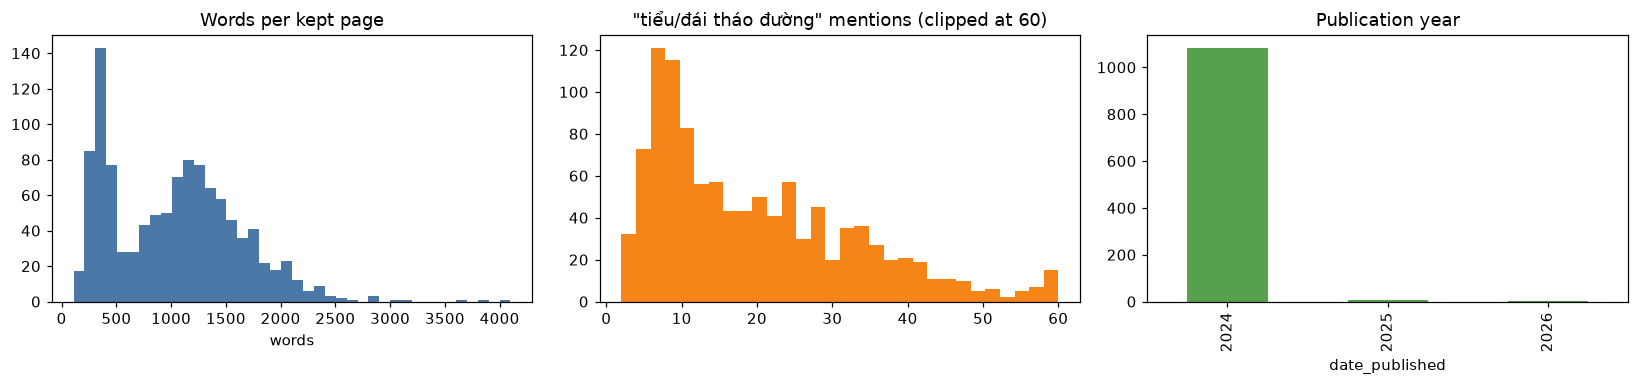

total words in corpus: 1,130,914   median page: 1044 words


In [5]:
kept = idx[idx.relevant]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(kept.n_words, bins=40, color="#4c78a8"); ax[0].set_title("Words per kept page"); ax[0].set_xlabel("words")
ax[1].hist(kept.core_mentions.clip(upper=60), bins=30, color="#f58518"); ax[1].set_title('"tiểu/đái tháo đường" mentions (clipped at 60)')
years = pd.to_datetime(kept.date_published, errors="coerce").dt.year.dropna().astype(int)
years.value_counts().sort_index().plot.bar(ax=ax[2], color="#54a24b"); ax[2].set_title("Publication year")
plt.tight_layout(); plt.show()
print(f"total words in corpus: {kept.n_words.sum():,}   median page: {kept.n_words.median():.0f} words")

### 2.4 What one saved page looks like, and why it is saved this way

The crawler does not save the raw HTML of the page. Raw HTML contains menus, advertisements, booking forms, the footer, scripts and so on; the article itself is maybe a quarter of it. Instead the crawler finds the article body and splits it into **sections**. For each section it saves three things: the **heading** the section sits under, its **paragraphs**, and its **bullet points** as separate items.

Keeping the heading is the most important design decision in the whole project, and the reason will become clear in Part 3. The heading tells us *what kind of information* the text below it contains. A bullet point that says "Mệt mỏi" (fatigue) means something completely different under the heading "Triệu chứng" (symptoms) than under "Tác dụng phụ của thuốc" (side effects of the drug). Without the heading we would not know which.

The text at the end of articles that is not part of the article ("Để đặt lịch khám tại viện, Quý khách vui lòng bấm số HOTLINE…", "Xem thêm:" followed by links to other articles) is cut off. If we kept it, every article would "mention" the same booking words, and links to related articles would bring in words from other topics.

Below is Vinmec's official disease page for type 2 diabetes, as it is saved. You can see the section headings and the first bullet points of each section.

In [6]:
page = json.loads((RAW / "pages" / "tieu-duong-tuyp-2-3042.json").read_text())
print("title:", page["title"]); print("url:  ", page["url"]); print("type: ", page["page_type"], "\n")
for s in page["sections"]:
    print(f"## {s['heading']}   ({len(s['paragraphs'])} paragraphs, {len(s['bullets'])} bullets)")
    for b in s["bullets"][:4]:
        print("     •", b[:110])

title: Tiểu đường tuýp 2: Nguyên nhân, triệu chứng, chẩn đoán và điều trị
url:   https://www.vinmec.com/vie/benh/tieu-duong-tuyp-2-3042
type:  disease 

## Tổng quan bệnh Tiểu đường tuýp 2   (4 paragraphs, 0 bullets)
## Nguyên nhân bệnh Tiểu đường tuýp 2   (1 paragraphs, 0 bullets)
## Triệu chứng bệnh Tiểu đường tuýp 2   (3 paragraphs, 4 bullets)
     • Ăn nhiều
     • Uống nhiều (hay khát nước)
     • Tiểu nhiều (do đường trong nước tiểu cao, gây lợi niệu thẩm thấu)
     • Gầy nhiều (gầy sút cân): bệnh nhân tiểu đường tuýp 2 thường có thể trạng béo, nhưng khi có triệu chứng tăng đư
## Biến chứng cấp tính   (1 paragraphs, 0 bullets)
## Biến chứng mạn tính   (0 paragraphs, 6 bullets)
     • Nhìn mờ (do biến chứng võng mạc, đục thủy tinh thể)
     • Đau ngực thường không điển hình (do biến chứng mạch vành)
     • Tê bì dị cảm ở bàn chân (biến chứng thần kinh)
     • Loét, nhiễm trùng bàn chân
## Đối tượng nguy cơ bệnh Tiểu đường tuýp 2   (0 paragraphs, 8 bullets)
     • Béo phì: tình trạ

## 3. Extraction: from text to facts

This is the heart of the project, the program `kg/extract.py`. Its job is to read 1,096 articles and produce facts of the form (subject, relation, object), without a human reading the articles.

### Why not let every bullet point become a node?

The simplest idea would be: take every bullet point under "Triệu chứng" and make it a Symptom node. On the type 2 page that would give nodes like "Ăn nhiều" and "Uống nhiều (hay khát nước)", which looks fine. But look at a bullet under "điều trị" on the type 1 page:

> *"Kiểm soát đường huyết: đối với tuýp 1 thì kiểm soát bằng insulin ngoại sinh là chủ yếu. Dùng theo phác đồ, tuân thủ giờ tiêm và liều lượng tránh bị tụt đường huyết. Các loại insulin gồm có…"*

That is 60 words. As a node it is useless: no other article will ever write exactly the same 60 words, so it will never connect to anything, and no question will ever match it. Even short bullets differ between articles: one writes "uống nhiều", another "khát nước", another "hay khát". As separate nodes, the fact "diabetes causes thirst" would be split into three weak pieces that never meet.

So instead of copying text into the graph, we decide **in advance** which things the graph can contain, give each one clean name, and then search the text for any of the ways it can be written. This fixed list is called the **vocabulary**.

### How extraction works, in three questions

For every page, and for every section of that page, the extractor answers three questions:

1. **Which diabetes is this page about?** That becomes the subject of the facts. (Type 1, type 2, gestational, prediabetes, or diabetes in general.)
2. **What kind of information is allowed in this section?** This is decided by the section heading. Under "Triệu chứng" we may find symptoms; under "Điều trị" we may find drugs.
3. **Which vocabulary entries are mentioned in this section's text?** Those become the objects of the facts.

Each fact found on a page counts as one **vote** from that page. At the end, the votes from all pages are added up, and a fact only enters the graph if enough different pages voted for it. The following sections explain each step and the reasons behind it.

### 3.1 The vocabulary (`kg/vocab.py`)

Every vocabulary entry has three parts: a clean **canonical name** that becomes the node in the graph, a **type**, and a list of **aliases**, the different ways Vietnamese articles actually write the same thing:

| canonical name | type | aliases searched for in the text |
|---|---|---|
| Khát nhiều | Symptom | khát nhiều, uống nhiều, khát nước, hay khát, khô miệng |
| Metformin | Drug | metformin, glucophage (a brand name) |
| Bệnh võng mạc | Complication | võng mạc, biến chứng mắt, mù lòa |

Turning many different ways of writing something into one single node is called **entity normalisation**. It is what makes the evidence add up. If one article says "uống nhiều" and another says "khát nước", both now vote for the same fact *(diabetes, HAS_SYMPTOM, Khát nhiều)*, and the graph knows that two articles agree.

The vocabulary was written by hand from the topics that appear in the articles: the classic symptoms, the risk factors listed on Vinmec's pages, the acute and chronic complications, the standard diagnostic tests, the drug names used in Vietnam (including brand names such as Diamicron, Januvia, Jardiance, because articles often use them), foods and lifestyle advice. Writing it by hand has a clear cost — anything not on the list can never be found — and a clear benefit: every node in the graph is clean and meaningful. Part 10 comes back to the cost.

In [7]:
import vocab
from extract import PATTERNS, LABEL, subject_of, allowed_labels, about_disease, matches

v = pd.DataFrame([(n, lab, len(al), ", ".join(al[:5])) for n, (lab, al) in vocab.VOCAB.items()],
                 columns=["entity", "type", "n_aliases", "first aliases"])
print(f"{len(v)} vocabulary entities, {v.n_aliases.sum()} aliases")
display(v.groupby("type").agg(entities=("entity", "count"), aliases=("n_aliases", "sum")).sort_values("entities", ascending=False))
display(v.sample(8, random_state=1))

106 vocabulary entities, 320 aliases


,entities,aliases
type,,
Drug,22,42
Complication,19,52
RiskFactor,17,52
Food,16,66
Symptom,16,56
Test,10,35
Lifestyle,6,17


,entity,type,n_aliases,first aliases
66,Insulin lispro,Drug,2,"lispro, humalog"
35,Tăng áp lực thẩm thấu,Complication,2,"tăng áp lực thẩm thấu, tăng áp lực thẩm thấu máu"
59,Máy đo đường huyết,Test,4,"máy đo đường huyết, tự theo dõi đường huyết, đo đường huyết tại nhà, cgm"
77,Canagliflozin,Drug,1,canagliflozin
39,Tăng nhãn áp,Complication,3,"tăng nhãn áp, glaucoma, cườm nước"
56,Xét nghiệm nước tiểu,Test,4,"xét nghiệm nước tiểu, tổng phân tích nước tiểu, đường niệu, ceton niệu"
55,Đường huyết ngẫu nhiên,Test,3,"đường huyết bất kỳ, đường huyết bất kì, đường huyết ngẫu nhiên"
87,Cá béo,Food,5,"cá hồi, cá thu, cá béo, omega-3, omega 3"


### 3.2 How an alias is found in the text

For each vocabulary entry, all its aliases are combined into one search pattern (a *regular expression*). Two details of this pattern matter a lot.

**First: the alias must be a whole word, not part of a longer word.** Vietnamese is written with spaces between syllables, so many aliases are a single short syllable, and short syllables appear inside other words all the time. Without protection, the fruit alias *"lê"* (pear) would be found inside *"lên"* (to go up, as in "lên cân", gaining weight), and the alias *"bia"* (beer) inside *"biên"* (as in "biên độ"). The pattern therefore requires that the character before and after the alias is not a letter. In the demo below, "bệnh nhân lên cân" correctly finds no food, while "ăn quả lê" finds the fruit.

**Second: longer aliases are tried first.** The Symptom "Tiểu nhiều" has both the alias "đi tiểu thường xuyên" and the shorter "tiểu thường xuyên". If the short one were tried first, it would match first and the longer, more precise wording would never be used. Trying the longest first means the most specific wording always wins.

**Why the accents are kept.** All text is converted to lowercase so that "HbA1C" and "hba1c" are the same, but the accents are never removed. Removing them would bring back the exact problem we saw with the URLs: *tiểu đường* and *tiểu dương* would become the same word.

**What this does not solve.** Some aliases are a complete word on their own that also has a second meaning. The fruit alias *"táo"* (apple) is a whole word in *"táo bón"* (constipation), so the word-boundary rule cannot stop it; the last line of the demo shows this false match. What protects us here is the next rule (3.3): a food alias only counts inside sections about diet, and constipation is rarely discussed in a section about what to eat. The problem is reduced, not eliminated, and it is listed in the limitations.

Here is the matching applied to a real sentence from the type 1 disease page.

In [8]:
sentence = "Đường huyết lúc đói (nhịn ăn >8-14h) >7 mmol trong 2 buổi sáng khác nhau; HbA1C >6,5%, kèm uống nhiều, tiểu nhiều."
print(sentence, "\n")
for lab in ["Test", "Symptom", "Drug"]:
    print(f"{lab:8s} →", matches(sentence, {lab}))

print("\nWord boundary demo:")
for text in ["bệnh nhân lên cân", "ăn quả lê", "uống bia", "bị táo bón kéo dài"]:
    print(f"  {text!r:22} Food matches → {matches(text, {'Food'})}")

Đường huyết lúc đói (nhịn ăn >8-14h) >7 mmol trong 2 buổi sáng khác nhau; HbA1C >6,5%, kèm uống nhiều, tiểu nhiều. 

Test     → ['HbA1c', 'Đường huyết lúc đói']
Symptom  → ['Khát nhiều', 'Tiểu nhiều']
Drug     → []

Word boundary demo:
  'bệnh nhân lên cân'    Food matches → []
  'ăn quả lê'            Food matches → ['Trái cây ít ngọt']
  'uống bia'             Food matches → ['Rượu bia']
  'bị táo bón kéo dài'   Food matches → ['Trái cây ít ngọt']


### 3.3 The section rule: the heading decides what may be extracted

Finding a vocabulary word somewhere in an article does not mean the article states a fact about it. Some real examples from the corpus:

- *"mệt mỏi"* (fatigue) appears in a diet article: "ăn sáng đầy đủ giúp bạn đỡ mệt mỏi". That does not mean fatigue is a symptom of diabetes in this article.
- *"tăng huyết áp"* (high blood pressure) appears in drug paragraphs as a condition the drug should not be combined with.
- Almost every article mentions *"insulin"* while explaining how blood sugar works, not because insulin is the treatment being discussed.

If we accepted every match anywhere, the graph would say that diabetes has dozens of symptoms that are really just words that happened to appear. So a match only counts when the **section heading** says that this section is about that kind of information. This works because health articles, especially on a hospital website, are organised by exactly these headings: "Triệu chứng", "Nguyên nhân", "Biến chứng", "Chẩn đoán", "Điều trị", "Chế độ ăn". The structure of the article tells us what the bullets mean.

| the heading contains words like | then we may extract | which produces the relation |
|---|---|---|
| triệu chứng, dấu hiệu, biểu hiện, nhận biết | symptoms | HAS_SYMPTOM |
| nguyên nhân, nguy cơ, đối tượng, yếu tố, ai dễ | risk factors | HAS_RISK_FACTOR |
| biến chứng, nguy hiểm, hậu quả, ảnh hưởng | complications | HAS_COMPLICATION |
| chẩn đoán, xét nghiệm, chỉ số, kiểm tra, theo dõi | tests | DIAGNOSED_BY |
| điều trị, thuốc, insulin, kiểm soát | drugs and lifestyle measures | TREATED_BY, MANAGED_BY |
| phòng ngừa, lối sống, lưu ý | lifestyle measures | MANAGED_BY |
| ăn, thực phẩm, dinh dưỡng, thực đơn, kiêng | foods | RECOMMENDS_FOOD / AVOIDS_FOOD |

A section whose heading has none of these words (for example "Tổng quan", the overview) produces no facts at all. That is intentional: overviews mention everything briefly, and we prefer to miss a fact than to invent one.

**An extra check for symptoms and risk factors.** The first version of this rule had a weakness that the quality check in Part 9 revealed. A heading can contain "nguyên nhân" or "nguy cơ" and still not be about diabetes itself:

- *"Một số nguyên nhân gây ngứa bàn tay và bàn chân"* lists the causes of **itching**;
- *"Yếu tố nguy cơ gây tai biến mạch máu não ở người tiểu đường"* lists the risk factors for a **stroke** in people who already have diabetes;
- *"Làm gì để giảm thiểu nguy cơ tim mạch…"* is advice on **reducing** heart risk.

Taking the bullets under these headings as risk factors *of diabetes* produced wrong facts, for example "high cholesterol is a risk factor of diabetes", when the article actually said it is a risk factor of the kidney complication. The underlying reason is that a symptom or risk factor always belongs to *something*, and the heading names what that something is. So, for symptoms and risk factors only, the heading must also pass a check (the function `about_disease()`):

- it must name diabetes (tiểu đường, đái tháo đường, tuýp, type, bệnh…) **or** be short and general, like "Triệu chứng" or "Ai dễ bị?", where there is nothing else it could be about; and
- it must **not** name another topic (biến chứng, thận, mắt, thần kinh, tim mạch, ngứa, tai biến, hôn mê…), because then the symptoms or causes belong to that topic; and
- it must not be about reducing a risk.

The table below shows real headings from the corpus and what the rule decides for each.

In [9]:
headings = [
    "Triệu chứng bệnh Tiểu đường tuýp 2",
    "Đối tượng nguy cơ bệnh Tiểu đường tuýp 1",
    "3. Ai dễ bị tiền tiểu đường?",
    "Các biện pháp điều trị bệnh Tiểu đường tuýp 1",
    "2.2. Một số thực phẩm mẹ bầu mắc bệnh tiểu đường thai kỳ cần tránh",
    "3. Một số nguyên nhân gây ngứa bàn tay và bàn chân",
    "2. Yếu tố nguy cơ gây tai biến mạch máu não ở người tiểu đường",
    "4. Làm gì để giảm thiểu nguy cơ tim mạch ở bệnh nhân tiểu đường?",
    "Biến chứng mạn tính",
]
display(pd.DataFrame([(h, about_disease(h), sorted(allowed_labels(h))) for h in headings],
                     columns=["section heading", "about diabetes itself?", "allowed entity types"]))

,section heading,about diabetes itself?,allowed entity types
0,Triệu chứng bệnh Tiểu đường tuýp 2,True,[Symptom]
1,Đối tượng nguy cơ bệnh Tiểu đường tuýp 1,True,[RiskFactor]
2,3. Ai dễ bị tiền tiểu đường?,True,[RiskFactor]
3,Các biện pháp điều trị bệnh Tiểu đường tuýp 1,True,"[Drug, Lifestyle]"
4,2.2. Một số thực phẩm mẹ bầu mắc bệnh tiểu đường thai kỳ cần tránh,True,[Food]
5,3. Một số nguyên nhân gây ngứa bàn tay và bàn chân,False,[]
6,2. Yếu tố nguy cơ gây tai biến mạch máu não ở người tiểu đường,False,[]
7,4. Làm gì để giảm thiểu nguy cơ tim mạch ở bệnh nhân tiểu đường?,False,[]
8,Biến chứng mạn tính,False,[Complication]


### 3.4 Which diabetes is the subject of the facts?

Diabetes is not one disease. Type 1 is an autoimmune disease where the body destroys its own insulin-producing cells, usually starting in childhood. Type 2 develops slowly in adults, mostly linked to weight and lifestyle. Gestational diabetes appears during pregnancy and usually disappears after birth. Prediabetes is the stage before type 2. Their symptoms, causes and treatments overlap but are not the same: "autoimmune destruction of beta cells" is a cause of type 1 only; "pre-eclampsia" is a complication of gestational diabetes only. If every fact were attached to one single "diabetes" node, these differences would be lost.

So each page is assigned a subject from its **title**. The title is used because it is the author's own short statement of what the article is about, and it is much more reliable than counting words in the body (an article about type 2 often mentions type 1 to compare). The rule checks the title for the words of each type and takes the first one found:

| the title contains | subject |
|---|---|
| tuýp 1 / type 1 / típ 1 | Đái tháo đường type 1 |
| tuýp 2 / type 2 / típ 2 | Đái tháo đường type 2 |
| thai kỳ / mang thai / mẹ bầu | Đái tháo đường thai kỳ |
| tiền đái tháo đường / tiền tiểu đường | Tiền đái tháo đường |
| none of these | Đái tháo đường (diabetes in general) |

This is a simplification, and it has a visible consequence: most articles do not name a type in the title ("12 lời khuyên về lối sống để tránh biến chứng tiểu đường"), so the general node receives most of the facts, even though in reality many of those articles are about type 2. We accept this because a wrong type would be worse than a general one: putting a type 2 fact on the general node is incomplete, but putting it on the type 1 node would be false.

Đái tháo đường type 2     ← Tiểu đường tuýp 2: Nguyên nhân, triệu chứng, chẩn đoán và điều trị
Đái tháo đường thai kỳ    ← Chế độ ăn cho người bị tiểu đường thai kỳ
Tiền đái tháo đường       ← Nguyên nhân và đối tượng nguy cơ tiền tiểu đường
Đái tháo đường            ← 12 lời khuyên về lối sống để tránh biến chứng tiểu đường



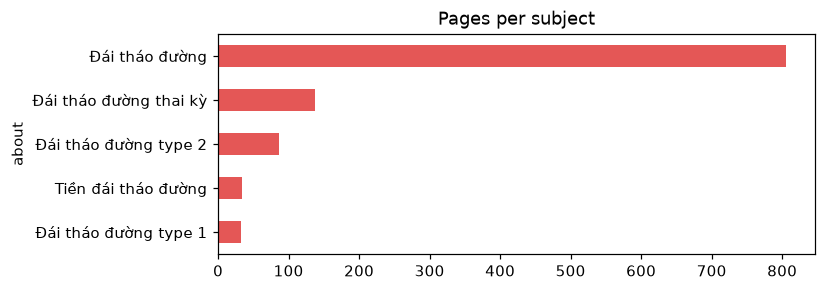

In [10]:
arts = pd.read_csv(PROC / "articles.csv")
for t in ["Tiểu đường tuýp 2: Nguyên nhân, triệu chứng, chẩn đoán và điều trị",
          "Chế độ ăn cho người bị tiểu đường thai kỳ",
          "Nguyên nhân và đối tượng nguy cơ tiền tiểu đường",
          "12 lời khuyên về lối sống để tránh biến chứng tiểu đường"]:
    print(f"{subject_of(t):25s} ← {t}")

print()
arts.about.value_counts().plot.barh(figsize=(7, 2.6), color="#e45756", title="Pages per subject")
plt.gca().invert_yaxis(); plt.show()

### 3.5 Walking through one page

Now we put the three steps together on the type 2 disease page and print, section by section, which kinds of information are allowed and which facts the page votes for. Look at three things in the output:

- the overview section ("Tổng quan") contributes nothing, because its heading has no keyword;
- the symptom section produces exactly the four classic symptoms listed on the page;
- the treatment section produces both drugs and lifestyle measures, because a heading like "điều trị" allows both.

In [11]:
subj = subject_of(page["title"])
print("subject:", subj, "\n")
for s in page["sections"]:
    labels = allowed_labels(s["heading"])
    found = sorted({e for unit in s["paragraphs"] + s["bullets"] for e in matches(unit, labels)})
    print(f"## {s['heading']}\n   allowed: {sorted(labels) or '—'}")
    for e in found:
        rel = vocab.RELATION_BY_LABEL.get(LABEL[e], "FOOD")
        print(f"   → ({subj}, {rel}, {e})")

subject: Đái tháo đường type 2 

## Tổng quan bệnh Tiểu đường tuýp 2
   allowed: —
## Nguyên nhân bệnh Tiểu đường tuýp 2
   allowed: ['RiskFactor']
   → (Đái tháo đường type 2, HAS_RISK_FACTOR, Di truyền / tiền sử gia đình)
## Triệu chứng bệnh Tiểu đường tuýp 2
   allowed: ['Symptom']
   → (Đái tháo đường type 2, HAS_SYMPTOM, Khát nhiều)
   → (Đái tháo đường type 2, HAS_SYMPTOM, Sụt cân)
   → (Đái tháo đường type 2, HAS_SYMPTOM, Tiểu nhiều)
   → (Đái tháo đường type 2, HAS_SYMPTOM, Ăn nhiều)
## Biến chứng cấp tính
   allowed: ['Complication']
   → (Đái tháo đường type 2, HAS_COMPLICATION, Nhiễm toan ceton)
   → (Đái tháo đường type 2, HAS_COMPLICATION, Tăng áp lực thẩm thấu)
## Biến chứng mạn tính
   allowed: ['Complication']
   → (Đái tháo đường type 2, HAS_COMPLICATION, Bàn chân đái tháo đường)
   → (Đái tháo đường type 2, HAS_COMPLICATION, Bệnh thần kinh ngoại biên)
   → (Đái tháo đường type 2, HAS_COMPLICATION, Bệnh võng mạc)
   → (Đái tháo đường type 2, HAS_COMPLICATION, Liệt dạ d

### 3.6 Counting evidence: why one page is not enough

Every rule above can still make mistakes on a single page: an unusual heading, a sentence that mentions a symptom in passing, a bullet that lists something to compare with. If we trusted every single page, every one of those mistakes would become a fact in the graph.

The defence is to require **agreement between independent pages**. For every fact we keep the set of pages that voted for it. It is a *set*, so one page that mentions "khát nhiều" five times still counts as one vote; we count how many different articles state the fact, not how many times one article repeats it. The number of pages in that set is called the fact's **support**.

A fact enters the graph only if at least **two** different pages support it. The idea is the same as checking a claim with a second source: a stray mention in one article is probably noise, but two articles written separately that both state the same fact are much more likely to be right.

There are two exceptions, each with a reason:

- A fact from one of Vinmec's official **disease pages** is accepted even with support 1. These pages are short, structured medical summaries reviewed by the hospital, and their headings are exactly the standard ones, so the extraction from them is the most reliable we have.
- **Drug side effects** need at least **three** pages, because that extraction (3.8) works on single sentences and is noisier than the section-based extraction.

A small worked example: imagine three pages, A, B and C, all about type 2.

| page | facts it votes for |
|---|---|
| A | type 2 HAS_SYMPTOM Khát nhiều, type 2 HAS_SYMPTOM Mệt mỏi |
| B | type 2 HAS_SYMPTOM Khát nhiều |
| C | type 2 HAS_SYMPTOM Khát nhiều, type 2 HAS_SYMPTOM Run tay |

"Khát nhiều" is stated by all three pages, so its support is 3 and it is kept. "Mệt mỏi" and "Run tay" are each stated by only one page, so they are dropped.

The support number is not thrown away after this filter. It is stored on the fact in Neo4j, so later, when we ask questions, we can sort answers by how well documented they are, or ask only for facts that at least five articles agree on.

In [12]:
votes = {"A": [("type 2","HAS_SYMPTOM","Khát nhiều"), ("type 2","HAS_SYMPTOM","Mệt mỏi")],
         "B": [("type 2","HAS_SYMPTOM","Khát nhiều")],
         "C": [("type 2","HAS_SYMPTOM","Khát nhiều"), ("type 2","HAS_SYMPTOM","Run tay")]}
support = defaultdict(set)
for pg, triples in votes.items():
    for t in triples: support[t].add(pg)
for t, pages in support.items():
    print(f"{t[2]:12s} support={len(pages)}  pages={sorted(pages)}  {'kept' if len(pages) >= 2 else 'dropped'}")

Khát nhiều   support=3  pages=['A', 'B', 'C']  kept
Mệt mỏi      support=1  pages=['A']  dropped
Run tay      support=1  pages=['C']  dropped


### 3.7 Foods: recommended or to avoid?

For foods the graph has two relations, RECOMMENDS_FOOD and AVOIDS_FOOD. The first version tried to decide which one from the words in the sentence or heading: "nên ăn" (should eat) meant recommended, "kiêng", "tránh", "hạn chế", "không nên" meant avoid. It failed badly, and it is worth understanding why. Diet articles mix both kinds of advice in the same place. A heading like *"Thực phẩm mẹ bầu cần tránh và nên ăn"* contains both "tránh" and "nên ăn", and a single sentence often says "hạn chế đồ ngọt, thay vào đó nên ăn rau xanh". The output contained nonsense such as "gestational diabetes AVOIDS green vegetables".

The final rule is simpler and more reliable: whether a food is good or bad for diabetes is treated as a **property of the food itself**, written once in the vocabulary. Sweets, soft drinks, white rice and refined starch, very sweet fruit (durian, ripe mango, longan, jackfruit…), alcohol, fried food and processed meat are marked "avoid"; the rest are "recommended". The text then only tells us that the food is **discussed in a diet section** for that type of diabetes. This matches standard nutrition advice and what the articles say in almost all cases. The cost is that subtle advice ("fruit is fine in moderate amounts") cannot be represented.

### 3.8 Drug side effects

Side effects cannot use the section rule, because they appear anywhere: in drug sections, in complication sections, in general articles. Instead they are found **inside one sentence**. A sentence produces a side-effect fact only if it contains a drug, a symptom or complication, and a word that signals cause, such as *"tác dụng phụ"* (side effect), *"tác dụng không mong muốn"* (unwanted effect) or *"gây"* (causes). For example:

> "Insulin có thể **gây hạ đường huyết** nếu tiêm quá liều" → Insulin HAS_SIDE_EFFECT Hạ đường huyết

One important exception: sentences containing *"thiếu"* (lack of) or *"không đủ"* (not enough) are skipped. The sentence *"thiếu insulin gây nhiễm toan ceton"* has a drug, a complication and the word "gây", but it says that a **lack** of insulin causes ketoacidosis, which is the opposite of a side effect of taking insulin. Without this exception, the graph would warn that insulin causes the very condition it treats.

### 3.9 Background facts added by hand

Some knowledge is not something an article "states" in a section, but general medical classification that every doctor knows and that articles take for granted. Metformin belongs to the biguanide class; diabetic retinopathy affects the eye; the diagnostic threshold of HbA1c is 6.5 %. These facts are added by hand with the label `source = "curated"`, so they can always be told apart from facts extracted from the articles:

- each drug and its **drug class** (Metformin → Biguanide, Empagliflozin → SGLT2 inhibitor…);
- each complication and the **organ** it affects (retinopathy → eye, nephropathy → kidney…);
- each type of diabetes is a **subtype** of diabetes in general;
- the diagnostic **thresholds** stored on the test nodes, from the Vietnamese Ministry of Health 2020 guideline and the American Diabetes Association criteria that the Vinmec pages also quote.

These few facts are what make the most interesting questions possible. Without "retinopathy affects the eye", the graph could tell you that type 2 causes retinopathy, but it could not answer "which organs does type 2 damage?".

In [13]:
print("Side-effect rule on three sentences:\n")
for s in ["Insulin có thể gây hạ đường huyết nếu tiêm quá liều.",
          "Thiếu insulin gây nhiễm toan ceton.",
          "Metformin là thuốc đầu tay cho tiểu đường tuýp 2."]:
    low = s.lower()
    cue = any(c in low for c in ["tác dụng phụ", "tác dụng không mong muốn", " gây "])
    cause = "thiếu" in low or "không đủ" in low
    drugs, eff = matches(s, {"Drug"}), matches(s, {"Symptom", "Complication"})
    verdict = [(d, "HAS_SIDE_EFFECT", e) for d in drugs for e in eff] if cue and not cause else "no triple"
    print(f"  {s}\n     cue={cue} cause-sentence={cause} drugs={drugs} effects={eff} → {verdict}\n")

Side-effect rule on three sentences:

  Insulin có thể gây hạ đường huyết nếu tiêm quá liều.
     cue=True cause-sentence=False drugs=['Insulin'] effects=['Hạ đường huyết'] → [('Insulin', 'HAS_SIDE_EFFECT', 'Hạ đường huyết')]

  Thiếu insulin gây nhiễm toan ceton.
     cue=True cause-sentence=True drugs=['Insulin'] effects=['Nhiễm toan ceton'] → no triple

  Metformin là thuốc đầu tay cho tiểu đường tuýp 2.
     cue=False cause-sentence=False drugs=['Metformin'] effects=[] → no triple



## 4. The resulting graph

`extract.py` writes four CSV files. Each one has a clear job:

| file | one row is | why it exists |
|---|---|---|
| `entities.csv` | one entity: its name, type and (for tests) threshold | becomes the nodes |
| `triples.csv` | one fact: subject, relation, object, support, source, up to five example URLs | becomes the arrows between nodes |
| `articles.csv` | one crawled page: URL, title, subject | so every fact can be traced back to the articles it came from |
| `mentions.csv` | a pair (page, entity) for every entity mentioned anywhere on the page | a looser signal of which topics each article talks about |

The facts file uses the same `subject, relation, object` format as the lecture's exercise, with three extra columns. `support` says how many pages back the fact, `source` says whether it was extracted from Vinmec or added by hand, and `example_urls` lists up to five of the articles that state it. Those URLs are what make the graph explainable: for any fact you can open the original article and read the sentence yourself.

In [14]:
ent = pd.read_csv(PROC / "entities.csv")
tri = pd.read_csv(PROC / "triples.csv")
print(f"entities: {len(ent)}   triples: {len(tri)}   relation types: {tri.relation.nunique()}   entity types: {ent.label.nunique()}")
print(f"extracted from text: {(tri.source == 'vinmec').sum()}   curated: {(tri.source == 'curated').sum()}")
display(tri[tri.source == "vinmec"].sort_values("support", ascending=False).head(12)[["subject", "relation", "object", "support"]])

entities: 127   triples: 339   relation types: 12   entity types: 10
extracted from text: 301   curated: 38


,subject,relation,object,support
295,Đái tháo đường,TREATED_BY,Insulin,143
239,Đái tháo đường,MANAGED_BY,Tập thể dục đều đặn,114
240,Đái tháo đường,MANAGED_BY,Giảm cân,75
96,Đái tháo đường,HAS_COMPLICATION,Bệnh tim mạch,56
259,Đái tháo đường,RECOMMENDS_FOOD,Ngũ cốc nguyên hạt,54
16,Đái tháo đường,AVOIDS_FOOD,Rượu bia,48
17,Đái tháo đường,AVOIDS_FOOD,"Đồ ngọt, bánh kẹo",44
97,Đái tháo đường,HAS_COMPLICATION,Bệnh thần kinh ngoại biên,44
260,Đái tháo đường,RECOMMENDS_FOOD,Trái cây ít ngọt,44
261,Đái tháo đường,RECOMMENDS_FOOD,Rau xanh,43


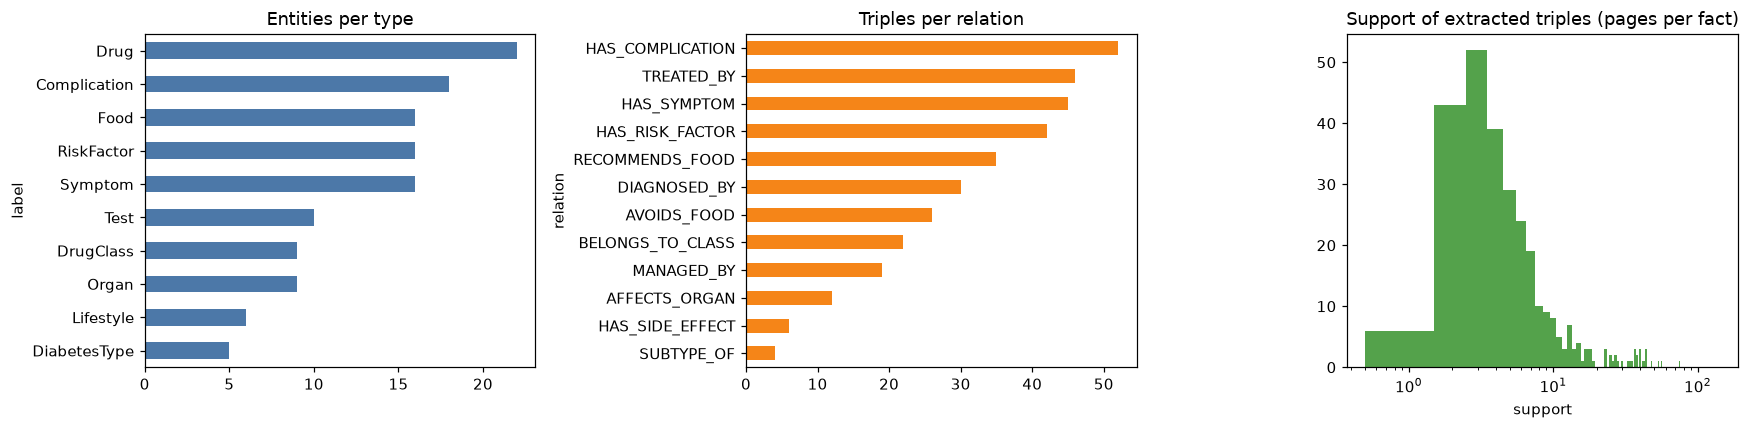

support quantiles: {0.25: 3.0, 0.5: 5.0, 0.75: 9.0, 0.9: 23.0}


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ent.label.value_counts().plot.barh(ax=ax[0], color="#4c78a8", title="Entities per type"); ax[0].invert_yaxis()
tri.relation.value_counts().plot.barh(ax=ax[1], color="#f58518", title="Triples per relation"); ax[1].invert_yaxis()
ext = tri[tri.source == "vinmec"]
ax[2].hist(ext.support, bins=np.arange(1, ext.support.max() + 2) - 0.5, color="#54a24b")
ax[2].set_xscale("log"); ax[2].set_title("Support of extracted triples (pages per fact)"); ax[2].set_xlabel("support")
plt.tight_layout(); plt.show()
print("support quantiles:", ext.support.quantile([.25, .5, .75, .9]).to_dict())

### Reading these charts

The left chart shows that drugs, complications, risk factors, symptoms and foods each have between 15 and 22 entities. That is roughly the size of the vocabulary for each type, which means almost every vocabulary entry was found in the articles at least once with enough support.

The right chart, the support of each fact, is the most informative. Most facts are backed by a handful of pages (the typical fact has 5), but a few are repeated by dozens: "diabetes is treated with insulin" by 143 pages, "managed by regular exercise" by 114. This shape is typical for a health website. The core message (exercise, diet, insulin, the main complications) is repeated in almost every article, while more specific facts, such as which drug class a newer medicine belongs to, are written once or twice. It also means the support number is a useful measure of how central a fact is to how Vinmec talks about diabetes.

### 4.1 Do the types of diabetes really differ in the graph?

If extracting a separate subject for each type (3.4) worked, the types should show different facts. The heatmaps below show, for each complication and each type, how many pages support the fact (darker = more pages, empty = no such fact).

Two things are visible. First, the general diabetes column is by far the darkest, which is the consequence of 3.4: most articles do not name a type. Second, gestational diabetes has its own clear pattern. Its strongest complications are hypoglycaemia (of the mother on treatment, and of the newborn), pre-eclampsia, premature birth and a very large baby — all pregnancy complications that the other types do not have — while type 1 and type 2 share the classic long-term complications of eyes, kidneys, nerves and heart. That is medically correct and shows that the subject rule captures real differences.

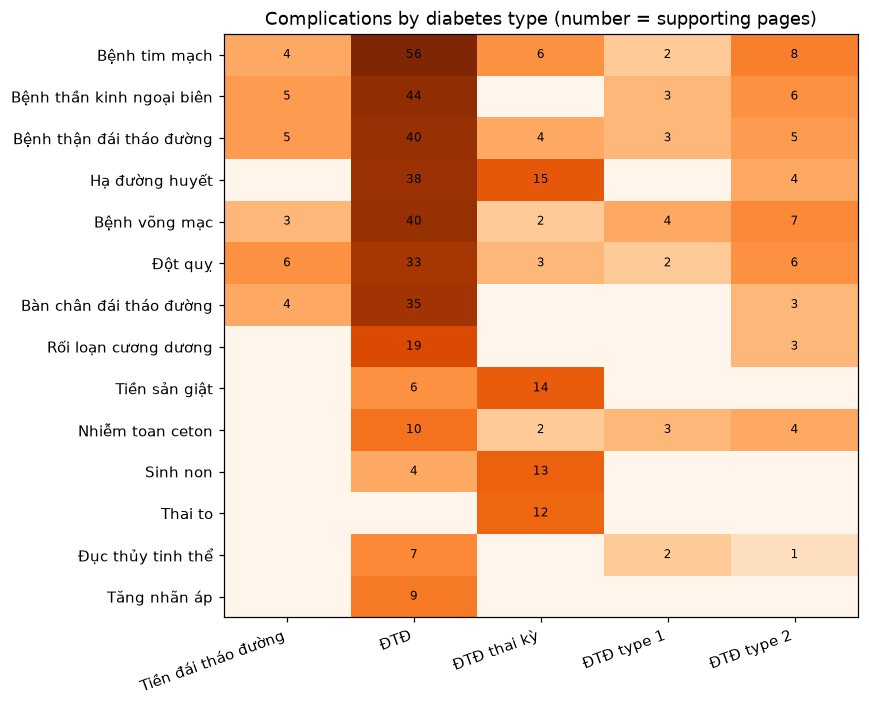

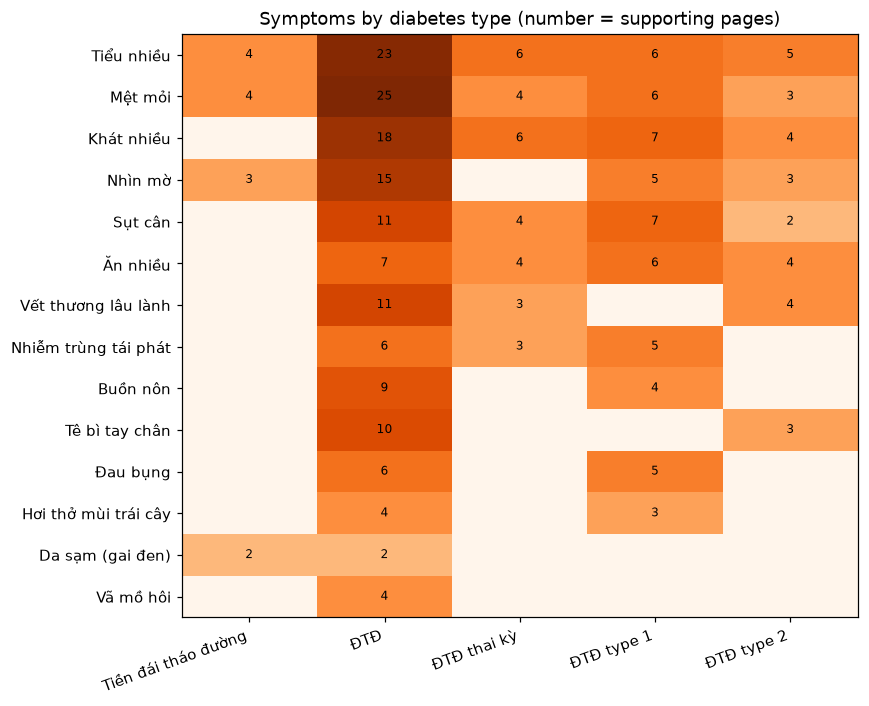

In [16]:
def heat(rel, title, top=14):
    sub = tri[tri.relation == rel].pivot_table(index="object", columns="subject", values="support", fill_value=0)
    sub = sub.loc[sub.sum(axis=1).sort_values(ascending=False).index[:top]]
    sub.columns = [c.replace("Đái tháo đường", "ĐTĐ") for c in sub.columns]
    plt.figure(figsize=(8, 0.38 * len(sub) + 1.2))
    plt.imshow(np.log1p(sub.values), cmap="Oranges", aspect="auto")
    plt.xticks(range(sub.shape[1]), sub.columns, rotation=20, ha="right"); plt.yticks(range(len(sub)), sub.index)
    for i in range(sub.shape[0]):
        for j in range(sub.shape[1]):
            if sub.values[i, j]: plt.text(j, i, int(sub.values[i, j]), ha="center", va="center", fontsize=8)
    plt.title(title + " (number = supporting pages)"); plt.tight_layout(); plt.show()

heat("HAS_COMPLICATION", "Complications by diabetes type")
heat("HAS_SYMPTOM", "Symptoms by diabetes type")

## 5. Storing the graph in Neo4j

### Why a graph database at all?

The NetworkX graph from Part 1 lives in the memory of the Python program. When the program ends, it is gone, and every program that wants to use the graph has to rebuild it from the CSV files. That is fine for 7 facts, but a real system needs the knowledge to be stored permanently, shared by several programs (a notebook, a chatbot, a web page), and answered quickly.

One could store the facts in an ordinary table database like MySQL, as a table with three columns. But questions about a graph are questions about **paths**: "start here, follow these arrows, then these". In a table database every step along a path is a *join* of the table with itself, the queries become long and hard to read, and they get slower as the table grows. A **graph database** stores each node together with direct links to its neighbours, so following an arrow is a direct jump, not a search. **Neo4j** is the most widely used graph database, and its query language **Cypher** is designed to describe paths, so a question looks almost like a drawing of the path.

### 5.1 How the data is modelled

```
(:Entity:Symptom {name})                 every vocabulary entity has the label Entity plus its own type
(:Entity:Test {name, threshold})
(:DiabetesType)-[:HAS_SYMPTOM {support, source, example_urls}]->(:Symptom)
(:Article {url, title, page_type, date})-[:ABOUT]->(:DiabetesType)
(:Article)-[:MENTIONS]->(:Entity)
```

Three decisions here deserve an explanation.

**Every entity has two labels**, `Entity` and its own type such as `Symptom`. The type label lets us ask for "all symptoms". The shared `Entity` label lets us make one rule for all of them: every entity name must be unique, so there can never be two different "Metformin" nodes. It also lets us write a question like "everything connected to Metformin" without knowing in advance what type each neighbour is.

**The evidence is stored on the arrows.** `support` and `example_urls` are properties of each relationship. This means a question can return the answer *and* how well documented it is *and* which articles state it, all in one step. If the evidence were stored elsewhere, every answer would need a second lookup.

**The articles are nodes in the graph too.** Each of the 1,096 articles is an `Article` node connected to the entities it mentions and to the diabetes type it is about. This keeps the link from the clean structured facts back to the messy original text. It is what lets us answer "where does this fact come from?", which is essential for a medical topic where nobody should trust an answer they cannot check.

### 5.2 How the data is loaded (`kg/load.py`)

```cypher
CREATE CONSTRAINT entity_name FOR (e:Entity) REQUIRE e.name IS UNIQUE;

UNWIND $rows AS r
MERGE (e:Entity {name: r.name}) SET e:Symptom;

UNWIND $rows AS r
MATCH (h:Entity {name: r.subject}), (t:Entity {name: r.object})
MERGE (h)-[x:HAS_SYMPTOM]->(t) SET x.support = r.support;
```

- **MERGE instead of CREATE.** CREATE always adds a new node, even if an identical one exists. MERGE first looks for it and only creates it if it is missing. This makes the loader safe to run any number of times: running it twice does not produce two copies of every fact.
- **UNWIND sends a whole batch at once.** Talking to the database has a fixed cost per request. Sending 10,000 mention links one by one would mean 10,000 round trips; UNWIND sends a list of rows in one request and lets the database loop over it, so everything loads in a few seconds.
- **The uniqueness rule also makes lookups fast.** To enforce that names are unique, Neo4j builds an index on the name. Every question that starts with "find the node called Metformin" uses that index and jumps straight to it, instead of checking all nodes one by one.
- **Relation types are written into the query text.** Cypher does not allow the type of an arrow to be a parameter, so the loader groups the facts by relation and builds one query per relation type.

The cell below connects to the database and counts what is in it.

In [17]:
from neo4j import GraphDatabase
driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", "diabetes123"))
driver.verify_connectivity()

def cy(query, **params):
    # run a Cypher query and return a DataFrame
    with driver.session() as s:
        return pd.DataFrame(s.run(query, **params).data())

nodes = cy("MATCH (n) UNWIND labels(n) AS l WITH l WHERE l <> 'Entity' RETURN l AS label, count(*) AS n ORDER BY n DESC")
rels = cy("MATCH ()-[r]->() RETURN type(r) AS relation, count(*) AS n ORDER BY n DESC")
display(nodes.T); display(rels.T)

,0,1,2,3,4,5,6,7,8,9,10
label,Article,Drug,Complication,Symptom,RiskFactor,Food,Test,DrugClass,Organ,Lifestyle,DiabetesType
n,1096,22,18,16,16,16,10,9,9,6,5


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
relation,MENTIONS,ABOUT,HAS_COMPLICATION,TREATED_BY,HAS_SYMPTOM,HAS_RISK_FACTOR,RECOMMENDS_FOOD,DIAGNOSED_BY,AVOIDS_FOOD,BELONGS_TO_CLASS,MANAGED_BY,AFFECTS_ORGAN,HAS_SIDE_EFFECT,SUBTYPE_OF
n,10083,1096,52,46,45,42,35,30,26,22,19,12,6,4


### 5.3 The shape of the graph: what kinds of questions it can answer

Neo4j can describe its own structure: which types of nodes are connected to which other types, by which kinds of arrows, and how many. The picture below draws that structure. Each circle is a type of entity, and each arrow is a kind of fact, with the number of such facts.

This picture is the best summary of what the graph *can* answer, because every arrow is a type of question. There is an arrow from DiabetesType to Test, so the graph can answer "how is it diagnosed?". There is an arrow from Complication to Organ, so after reaching a complication it can continue to the organ. There is no arrow from Food to Complication, so the graph cannot answer "which food prevents kidney disease?" — not because the articles never discuss it, but because we never extracted that kind of fact.

The picture also shows the layered structure of the graph: the diabetes types on the left, everything the articles say about them in the middle, and the hand-added classifications (drug classes and organs) on the right.

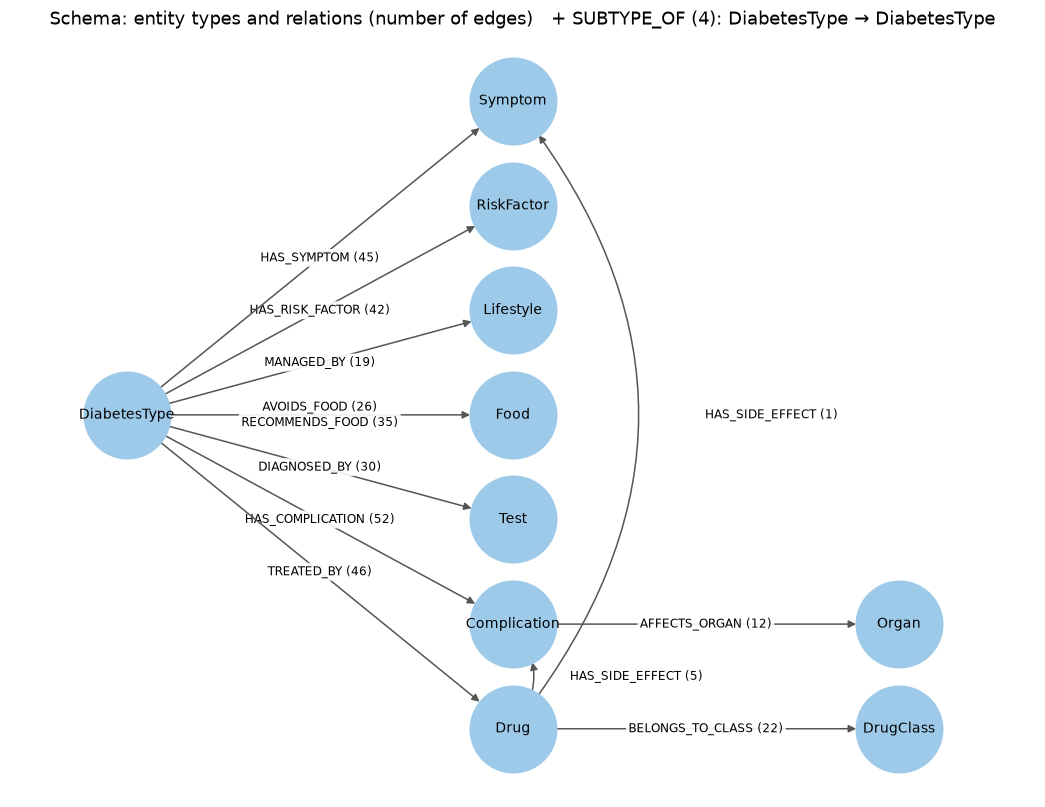

In [18]:
meta = cy('''
MATCH (a)-[r]->(b)
WHERE NOT a:Article
WITH [l IN labels(a) WHERE l <> 'Entity'][0] AS src, type(r) AS rel, [l IN labels(b) WHERE l <> 'Entity'][0] AS dst, count(*) AS n
RETURN src, rel, dst, n''')
# layered layout: diabetes types → what they point to → curated classifications
Y = 1.4   # vertical spacing
pos = {"DiabetesType": (0, 3 * Y), "Symptom": (4, 6 * Y), "RiskFactor": (4, 5 * Y), "Lifestyle": (4, 4 * Y),
       "Food": (4, 3 * Y), "Test": (4, 2 * Y), "Complication": (4, 1 * Y), "Drug": (4, 0),
       "Organ": (8, 1 * Y), "DrugClass": (8, 0)}
# several relation types between the same pair of types (e.g. RECOMMENDS_FOOD and AVOIDS_FOOD) share one arrow
pairs = defaultdict(list)
for r in meta.itertuples():
    if r.src != r.dst:
        pairs[(r.src, r.dst)].append(f"{r.rel} ({r.n})")
fig, ax = plt.subplots(figsize=(12, 9))
for (src, dst), labels in pairs.items():
    curved = src == "Drug" and dst in ("Symptom", "Complication")   # side effects run inside the middle column
    (x0, y0), (x1, y1) = pos[src], pos[dst]
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color="#555", lw=1, shrinkA=28, shrinkB=28,
                                connectionstyle="arc3,rad=0.4" if curved else "arc3"))
    if curved:   # the arc bulges to the right of the column, where there is free space
        lx, ly = x0 + 0.2 * (y1 - y0) + 1.0, (y0 + y1) / 2
    else:
        lx, ly = (x0 + x1) / 2, (y0 + y1) / 2
    ax.text(lx, ly, "\n".join(labels), fontsize=8, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))
for name, (x, y) in pos.items():
    ax.scatter(x, y, s=3200, color="#9ecae9", zorder=3)
    ax.text(x, y, name, ha="center", va="center", fontsize=9, zorder=4)
ax.set_xlim(-1.2, 9.4); ax.set_ylim(-0.9, 6 * Y + 0.9); ax.axis("off")
ax.set_title("Schema: entity types and relations (number of edges)   + SUBTYPE_OF (4): DiabetesType → DiabetesType")
plt.show()

## 6. Asking questions with Cypher

### How a Cypher question is written

Cypher describes the **shape of a path** using symbols that look like a drawing: round brackets for nodes, square brackets inside an arrow for relationships.

```cypher
MATCH (t:DiabetesType {name: 'Đái tháo đường type 2'})-[r:HAS_SYMPTOM]->(s:Symptom)
RETURN s.name, r.support
```

Read it from left to right: *find a node of type DiabetesType whose name is "type 2", follow an outgoing arrow of kind HAS_SYMPTOM, arriving at a node of type Symptom; give me the symptom's name and the arrow's support.* The letters `t`, `r`, `s` are names we give to the parts so we can use them in `RETURN`.

How does Neo4j answer it? It uses the name index to jump directly to the "type 2" node, then looks only at the arrows attached to that node. It never looks at the rest of the database. That is why graph questions stay fast however large the graph becomes: the work depends on how many arrows you follow, not on how big the database is.

All the questions below are also saved in `kg/queries.cypher`, so you can paste them into Neo4j Browser at http://localhost:7474 and see the results drawn as a graph.

### 6.1 One-hop: everything directly connected to Metformin

In [19]:
cy('''
MATCH (e:Entity {name: 'Metformin'})-[r]-(n:Entity)
RETURN startNode(r).name AS subject, type(r) AS relation, endNode(r).name AS object, r.support AS support, r.source AS source
ORDER BY support DESC''')

,subject,relation,object,support,source
0,Đái tháo đường,TREATED_BY,Metformin,37,vinmec
1,Đái tháo đường type 2,TREATED_BY,Metformin,11,vinmec
2,Tiền đái tháo đường,TREATED_BY,Metformin,8,vinmec
3,Metformin,HAS_SIDE_EFFECT,Hạ đường huyết,5,vinmec
4,Metformin,BELONGS_TO_CLASS,Biguanide,0,curated


The pattern `-[r]-` has no arrowhead, which means "an arrow in either direction". That is why we see both kinds of facts: the ones pointing into Metformin (type 2 *is treated by* Metformin) and the one pointing out of it (Metformin *belongs to* the biguanide class). For a question like "what do we know about X" the direction does not matter, so we ask for both.

Notice also the `support` column. The fact "diabetes is treated with Metformin" is stated by 37 articles, the side effect "hypoglycaemia" by only 5, and the drug class has support 0 because it was added by hand (`source = curated`), not counted from articles. Showing the support next to each fact lets the reader judge how solid each one is.

### 6.2 Two-hop: which organs can type 2 diabetes damage?

This is the question from Part 1, now on the real graph. The path is: type 2 → (HAS_COMPLICATION) → a complication → (AFFECTS_ORGAN) → an organ. No article contains the fact "type 2 damages the eye" in this form. The answer exists only because two kinds of facts meet at the complication node: an extracted one (type 2 causes retinopathy) and a hand-added one (retinopathy affects the eye). `collect()` gathers all the complications that lead to the same organ into one list, so each organ appears once with its reasons.

In [20]:
cy('''
MATCH (t:DiabetesType {name: 'Đái tháo đường type 2'})-[r:HAS_COMPLICATION]->(c)-[:AFFECTS_ORGAN]->(o:Organ)
RETURN o.name AS organ, collect(c.name) AS via_complications, sum(r.support) AS evidence
ORDER BY evidence DESC''')

,organ,via_complications,evidence
0,Thần kinh,"[Rối loạn cương dương, Bệnh thần kinh ngoại biên]",9
1,Mắt,"[Bệnh võng mạc, Đục thủy tinh thể]",8
2,Tim mạch,[Bệnh tim mạch],8
3,Não,[Đột quỵ],6
4,Thận,[Bệnh thận đái tháo đường],5
5,Bàn chân,[Bàn chân đái tháo đường],3
6,Dạ dày,[Liệt dạ dày],1


### 6.3 Comparing type 1 and type 2 symptoms

Here we take the symptom facts of both types and, for each symptom, collect which types it belongs to. A symptom with both types is shared; a symptom with only one type is specific to that type in the Vinmec articles.

The six classic symptoms (thirst, frequent urination, eating a lot, weight loss, fatigue, blurred vision) are shared, which is correct: they are caused by high blood sugar itself, whatever its cause. Most of the type 1-only symptoms — nausea, abdominal pain, fruity-smelling breath — are the signs of ketoacidosis, the dangerous acid build-up that happens when the body has almost no insulin, which is typical for type 1 at the time it is discovered. (Recurrent infections also appear only for type 1 here; that one is a general sign of high blood sugar that the type 2 articles simply did not list under a symptom heading.) The type 2-only symptoms — slow-healing wounds, numb hands and feet — appear after years of slightly high blood sugar, which matches type 2's slow, often unnoticed course. The graph has reproduced a real medical difference without anyone telling it.

In [21]:
cy('''
MATCH (t:DiabetesType)-[r:HAS_SYMPTOM]->(s:Symptom)
WHERE t.name IN ['Đái tháo đường type 1', 'Đái tháo đường type 2']
WITH s, collect(t.name) AS types, collect(r.support) AS sup
RETURN s.name AS symptom, CASE size(types) WHEN 2 THEN 'both' ELSE types[0] END AS found_in, sup AS support
ORDER BY found_in, symptom''')

,symptom,found_in,support
0,Khát nhiều,both,"[7, 4]"
1,Mệt mỏi,both,"[6, 3]"
2,Nhìn mờ,both,"[5, 3]"
3,Sụt cân,both,"[7, 2]"
4,Tiểu nhiều,both,"[6, 5]"
5,Ăn nhiều,both,"[6, 4]"
6,Buồn nôn,Đái tháo đường type 1,[4]
7,Hơi thở mùi trái cây,Đái tháo đường type 1,[3]
8,Nhiễm trùng tái phát,Đái tháo đường type 1,[5]
9,Đau bụng,Đái tháo đường type 1,[5]


### 6.4 A symptom checker

Given a list of symptoms, which type of diabetes do they point to? The question finds all symptom facts whose symptom is in the list, groups them by diabetes type, and ranks the types by **how many of the given symptoms they have**. When two types match the same number of symptoms, they are ordered by the total support of the matching facts, meaning: which type do the articles associate more strongly with these symptoms.

With the input {thirst, frequent urination, weight loss, blurred vision}, general diabetes, type 1 and type 2 all match all four, and general diabetes comes first because most articles are general (3.4). Gestational diabetes matches three.

This shows both the use and the limit of the graph. It can tell you which types are *associated* with these symptoms in the literature and how strongly. It cannot tell a patient which diabetes they have: the classic symptoms are shared by all types, and a diagnosis needs blood tests (which is exactly what the next question shows). The symptom checker is a way of retrieving information, not a diagnosis.

In [22]:
cy('''
WITH $input AS input
MATCH (t:DiabetesType)-[r:HAS_SYMPTOM]->(s:Symptom) WHERE s.name IN input
RETURN t.name AS type, count(s) AS matched, collect(s.name) AS symptoms, sum(r.support) AS evidence
ORDER BY matched DESC, evidence DESC''', input=["Khát nhiều", "Tiểu nhiều", "Sụt cân", "Nhìn mờ"])

,type,matched,symptoms,evidence
0,Đái tháo đường,4,"[Khát nhiều, Nhìn mờ, Sụt cân, Tiểu nhiều]",67
1,Đái tháo đường type 1,4,"[Khát nhiều, Nhìn mờ, Sụt cân, Tiểu nhiều]",25
2,Đái tháo đường type 2,4,"[Khát nhiều, Nhìn mờ, Sụt cân, Tiểu nhiều]",14
3,Đái tháo đường thai kỳ,3,"[Khát nhiều, Sụt cân, Tiểu nhiều]",16
4,Tiền đái tháo đường,2,"[Nhìn mờ, Tiểu nhiều]",7


### 6.5 Following a chain: from a risk factor to an organ

A three-step path: a risk factor ← (is a risk factor of) a diabetes type → (can cause) a complication → (affects) an organ. Each row of the answer is a complete chain of reasoning that can be shown to a user in plain words: *obesity is a risk factor for type 2 diabetes; type 2 diabetes can cause diabetic kidney disease; diabetic kidney disease damages the kidneys.*

This kind of chained explanation is the main thing a graph offers that a list of documents does not. Each step is a separate fact, possibly from different articles, and the graph connects them because they share a node.

In [23]:
cy('''
MATCH p = (rf:RiskFactor {name: 'Thừa cân, béo phì'})<-[:HAS_RISK_FACTOR]-(t:DiabetesType)
          -[:HAS_COMPLICATION]->(c:Complication)-[:AFFECTS_ORGAN]->(o:Organ {name: 'Thận'})
RETURN [n IN nodes(p) | n.name] AS path''')

,path
0,"[Thừa cân, béo phì, Đái tháo đường type 2, Bệnh thận đái tháo đường, Thận]"
1,"[Thừa cân, béo phì, Đái tháo đường, Bệnh thận đái tháo đường, Thận]"
2,"[Thừa cân, béo phì, Đái tháo đường thai kỳ, Bệnh thận đái tháo đường, Thận]"
3,"[Thừa cân, béo phì, Tiền đái tháo đường, Bệnh thận đái tháo đường, Thận]"


### 6.6 Diagnosis: which tests, and at what values?

This answer combines the two kinds of knowledge. The link "diabetes is diagnosed by HbA1c" was extracted from the articles; the threshold "6.5 % or more" is stored on the test node and was added by hand from the official guideline. Together they answer "how is diabetes diagnosed?" with real numbers. The `evidence` column shows that HbA1c and the glucose tolerance test are the tests the articles mention most.

In [24]:
cy('''
MATCH (t:DiabetesType)-[r:DIAGNOSED_BY]->(x:Test)
RETURN x.name AS test, x.threshold AS threshold, collect(t.name) AS used_for, sum(r.support) AS evidence
ORDER BY evidence DESC''')

,test,threshold,used_for,evidence
0,HbA1c,≥ 6.5%,"[Đái tháo đường, Tiền đái tháo đường, Đái tháo đường type 1, Đái tháo đường thai kỳ, Đái tháo đường type 2]",67
1,Nghiệm pháp dung nạp glucose (OGTT),2 giờ ≥ 11.1 mmol/L (200 mg/dL),"[Đái tháo đường type 2, Đái tháo đường, Tiền đái tháo đường, Đái tháo đường thai kỳ, Đái tháo đường type 1]",59
2,Đường huyết lúc đói,≥ 7.0 mmol/L (126 mg/dL),"[Đái tháo đường, Tiền đái tháo đường, Đái tháo đường thai kỳ, Đái tháo đường type 2, Đái tháo đường type 1]",51
3,Xét nghiệm nước tiểu,NaN,"[Đái tháo đường, Đái tháo đường type 2, Đái tháo đường type 1]",14
4,Soi đáy mắt,NaN,"[Đái tháo đường, Đái tháo đường type 2, Đái tháo đường type 1]",11
5,Đường huyết ngẫu nhiên,≥ 11.1 mmol/L kèm triệu chứng,"[Đái tháo đường type 1, Đái tháo đường, Đái tháo đường type 2]",11
6,Máy đo đường huyết,NaN,[Đái tháo đường],10
7,Mỡ máu (lipid),NaN,"[Đái tháo đường, Đái tháo đường type 2, Đái tháo đường type 1]",7
8,C-peptide,NaN,[Đái tháo đường],2
9,Kháng thể kháng đảo tụy,NaN,[Đái tháo đường type 1],1


### 6.7 Drugs grouped by class, with their side effects

Each drug is shown with its class (hand-added), the number of articles that mention it as a treatment, and any side effects extracted from sentences (3.8). Insulin is by far the most discussed treatment (143 articles), followed by Metformin (37), which matches clinical practice: Metformin is the first drug for type 2, and insulin is essential for type 1 and for advanced type 2.

Look carefully at insulin's side effects: one of them is *ketoacidosis*. That is wrong. Ketoacidosis is caused by a *lack* of insulin, not by taking it, and the "thiếu" filter from 3.8 did not catch every way this is phrased. This is a real extraction error left in the graph, and it is listed in the limitations.

In [25]:
cy('''
MATCH (d:Drug)-[:BELONGS_TO_CLASS]->(c:DrugClass)
OPTIONAL MATCH (d)-[se:HAS_SIDE_EFFECT]->(e)
OPTIONAL MATCH (:DiabetesType {name: 'Đái tháo đường'})-[tr:TREATED_BY]->(d)
RETURN c.name AS class, d.name AS drug, coalesce(tr.support, 0) AS articles, collect(e.name) AS side_effects
ORDER BY class, articles DESC''')

,class,drug,articles,side_effects
0,Biguanide,Metformin,37,[Hạ đường huyết]
1,Meglitinide,Repaglinide,6,[]
2,Nhóm Insulin,Insulin,143,"[Nhiễm toan ceton, Hạ đường huyết, Loãng xương, Buồn nôn]"
3,Nhóm Insulin,Insulin glargine,13,[]
4,Nhóm Insulin,Insulin aspart,11,[]
5,Nhóm Insulin,Insulin lispro,9,[]
6,Nhóm Insulin,Insulin NPH,6,[]
7,Sulfonylurea,Glimepiride,9,[]
8,Sulfonylurea,Gliclazide,8,[]
9,Sulfonylurea,Glibenclamide,5,[]


The question uses `OPTIONAL MATCH` for the side effects. A normal MATCH drops a drug completely if it has no side-effect fact, because the whole pattern must be found. OPTIONAL MATCH means "include this part if it exists, otherwise leave it empty", so drugs without side effects are still listed, with an empty list.

### 6.8 Diet for gestational diabetes

The foods discussed in diet sections of gestational-diabetes articles, split into recommended and to avoid (the split comes from the fixed food list in 3.7), with the number of articles for each. Sweets are the most discussed food to avoid, and green vegetables, eggs and whole grains the most recommended — consistent with the usual advice for pregnant women with diabetes.

In [26]:
cy('''
MATCH (:DiabetesType {name: 'Đái tháo đường thai kỳ'})-[r:RECOMMENDS_FOOD|AVOIDS_FOOD]->(f:Food)
RETURN type(r) AS advice, f.name AS food, r.support AS articles
ORDER BY advice, articles DESC''')

,advice,food,articles
0,AVOIDS_FOOD,"Đồ ngọt, bánh kẹo",14
1,AVOIDS_FOOD,Nước ngọt có ga,7
2,AVOIDS_FOOD,Thịt chế biến sẵn,7
3,AVOIDS_FOOD,Rượu bia,6
4,AVOIDS_FOOD,"Đồ chiên rán, mỡ động vật",6
5,AVOIDS_FOOD,Trái cây nhiều đường,4
6,AVOIDS_FOOD,"Cơm trắng, tinh bột tinh chế",2
7,RECOMMENDS_FOOD,Rau xanh,13
8,RECOMMENDS_FOOD,Trứng,12
9,RECOMMENDS_FOOD,Ngũ cốc nguyên hạt,10


### 6.9 Where does a fact come from?

Every fact stores up to five example article URLs. Here we take the fact "type 2 can cause diabetic kidney disease", unpack its URLs and look up the article nodes to get their titles. The result is a list of real Vinmec articles that state the fact, which anyone can open and read.

This is the property that makes a knowledge graph trustworthy for a topic like health. A language model can say something fluent and wrong without any way to check it. Here every answer can be traced back to its source.

In [27]:
cy('''
MATCH (:DiabetesType {name: 'Đái tháo đường type 2'})-[r:HAS_COMPLICATION]->(:Complication {name: 'Bệnh thận đái tháo đường'})
UNWIND r.example_urls AS url
MATCH (a:Article {url: url})
RETURN a.title AS article, a.url AS url''')

,article,url
0,Bệnh tiểu đường type 2 có nguy hiểm không?,https://www.vinmec.com/vie/bai-viet/benh-tieu-duong-type-2-co-nguy-hiem-khong-vi
1,"Bệnh tiểu đường type 2: Nguyên nhân, biến chứng và phòng bệnh",https://www.vinmec.com/vie/bai-viet/benh-tieu-duong-type-2-nguyen-nhan-bien-chung-nguy-hiem-doi-tuong-de-mac-nhat-vi
2,Các biến chứng nguy hiểm của bệnh đái tháo đường type 2,https://www.vinmec.com/vie/bai-viet/cac-bien-chung-nguy-hiem-cua-benh-dai-thao-duong-type-2-vi
3,Cách tự nhiên điều trị bệnh tiểu đường type 2 với những thực phẩm hàng ngày,https://www.vinmec.com/vie/bai-viet/cach-tu-nhien-dieu-tri-benh-tieu-duong-type-2-voi-nhung-thuc-pham-hang-ngay-vi
4,Triệu chứng sớm của đái tháo đường type 2,https://www.vinmec.com/vie/bai-viet/dau-hieu-som-cua-tieu-duong-type-2-vi


### 6.10 Which complications are written about together?

The MENTIONS links (article → every entity it mentions anywhere) give a second, looser kind of information: which topics appear in the same articles. Here we count, for every pair of complications, how many articles mention both.

This is not a fact about diabetes — appearing in the same article does not mean one causes the other — but it shows how Vinmec writes about the disease. Cardiovascular disease and hypoglycaemia appear together most often, simply because each of them is mentioned in a very large share of all articles. That is a general weakness of counting co-occurrence: pairs of common topics always come first, whether or not they are really related. To find pairs that are *unusually* often together, the counts would have to be compared with what is expected from how common each topic is on its own.

In [28]:
cy('''
MATCH (a:Article)-[:MENTIONS]->(c1:Complication), (a)-[:MENTIONS]->(c2:Complication)
WHERE c1.name < c2.name
RETURN c1.name AS complication_1, c2.name AS complication_2, count(a) AS articles_together
ORDER BY articles_together DESC LIMIT 10''')

,complication_1,complication_2,articles_together
0,Bệnh tim mạch,Hạ đường huyết,170
1,Bệnh thận đái tháo đường,Bệnh tim mạch,163
2,Bệnh tim mạch,Đột quỵ,139
3,Bệnh thận đái tháo đường,Hạ đường huyết,116
4,Bệnh thần kinh ngoại biên,Bệnh tim mạch,110
5,Bệnh thận đái tháo đường,Bệnh võng mạc,107
6,Bệnh thần kinh ngoại biên,Bệnh thận đái tháo đường,100
7,Bệnh tim mạch,Bệnh võng mạc,98
8,Bệnh thận đái tháo đường,Đột quỵ,95
9,Bệnh thần kinh ngoại biên,Bệnh võng mạc,84


## 7. Graph retrieval: `graph_facts(entity, hops)`

In a complete question-answering system (the lecture's KG + RAG architecture), a language model writes the final answer, and the graph's job is to give it a small set of relevant, reliable facts to base the answer on. The function in `kg/retriever.py` does exactly that:

1. find the node for the entity named in the question;
2. collect the facts within one step (or two steps) of it;
3. turn each fact back into a short sentence, "subject RELATION object.";
4. sort them by support, so the best-documented facts come first, and return at most 30.

Why not simply return everything that is connected? Because in a graph, almost everything is connected to everything within a few steps, especially through hub nodes. The output below shows it: one step from "Hạ đường huyết" (hypoglycaemia) gives 5 precise facts; two steps give 230, because one of the first-step neighbours is "Đái tháo đường", which is connected to almost the whole graph. Giving 230 facts to a language model for a question about hypoglycaemia would bury the 5 relevant ones in noise. This is the lecture's "graph retrieval too broad" problem, and the solution is the one used here: start from the entity in the question, stay within one or two steps, and rank and cut the list.

In [29]:
from retriever import graph_facts
print("1 hop from 'Hạ đường huyết':")
for f in graph_facts(driver, "Hạ đường huyết", hops=1): print("  ", f)

two = graph_facts(driver, "Hạ đường huyết", hops=2, limit=1000)
print(f"\n2 hops: {len(two)} facts (only the first 30 would be returned) — e.g.")
for f in two[5:12]: print("  ", f)

1 hop from 'Hạ đường huyết':
   Đái tháo đường HAS_COMPLICATION Hạ đường huyết.
   Insulin HAS_SIDE_EFFECT Hạ đường huyết.
   Đái tháo đường thai kỳ HAS_COMPLICATION Hạ đường huyết.
   Metformin HAS_SIDE_EFFECT Hạ đường huyết.
   Đái tháo đường type 2 HAS_COMPLICATION Hạ đường huyết.

2 hops: 230 facts (only the first 30 would be returned) — e.g.
   Đái tháo đường TREATED_BY Insulin.
   Đái tháo đường MANAGED_BY Tập thể dục đều đặn.
   Đái tháo đường MANAGED_BY Giảm cân.
   Đái tháo đường HAS_COMPLICATION Bệnh tim mạch.
   Đái tháo đường RECOMMENDS_FOOD Ngũ cốc nguyên hạt.
   Đái tháo đường AVOIDS_FOOD Rượu bia.
   Đái tháo đường AVOIDS_FOOD Đồ ngọt, bánh kẹo.


## 8. Drawing the graph and finding the important entities

For drawing and for measuring the graph we rebuild it in NetworkX from the same CSV files that were loaded into Neo4j, so both contain exactly the same facts.

### 8.1 The whole graph

In the picture, the colour of a dot shows its type and the size shows how many facts it is part of. The structure is easy to see. The five diabetes-type dots are the large hubs in the middle, because almost every extracted fact starts from one of them. The symptoms, complications, drugs, foods and tests are arranged around them. The hand-added facts form small side chains at the edge: drug → drug class, complication → organ.

With 127 dots and 339 arrows, the picture is dense but not hopeless. Out of all the arrows that could possibly exist between 127 dots, only about 2 % are present: each entity is connected to a few others, not to everything. Graphs of real knowledge are almost always this sparse.

127 nodes, 339 edges, density = 0.021


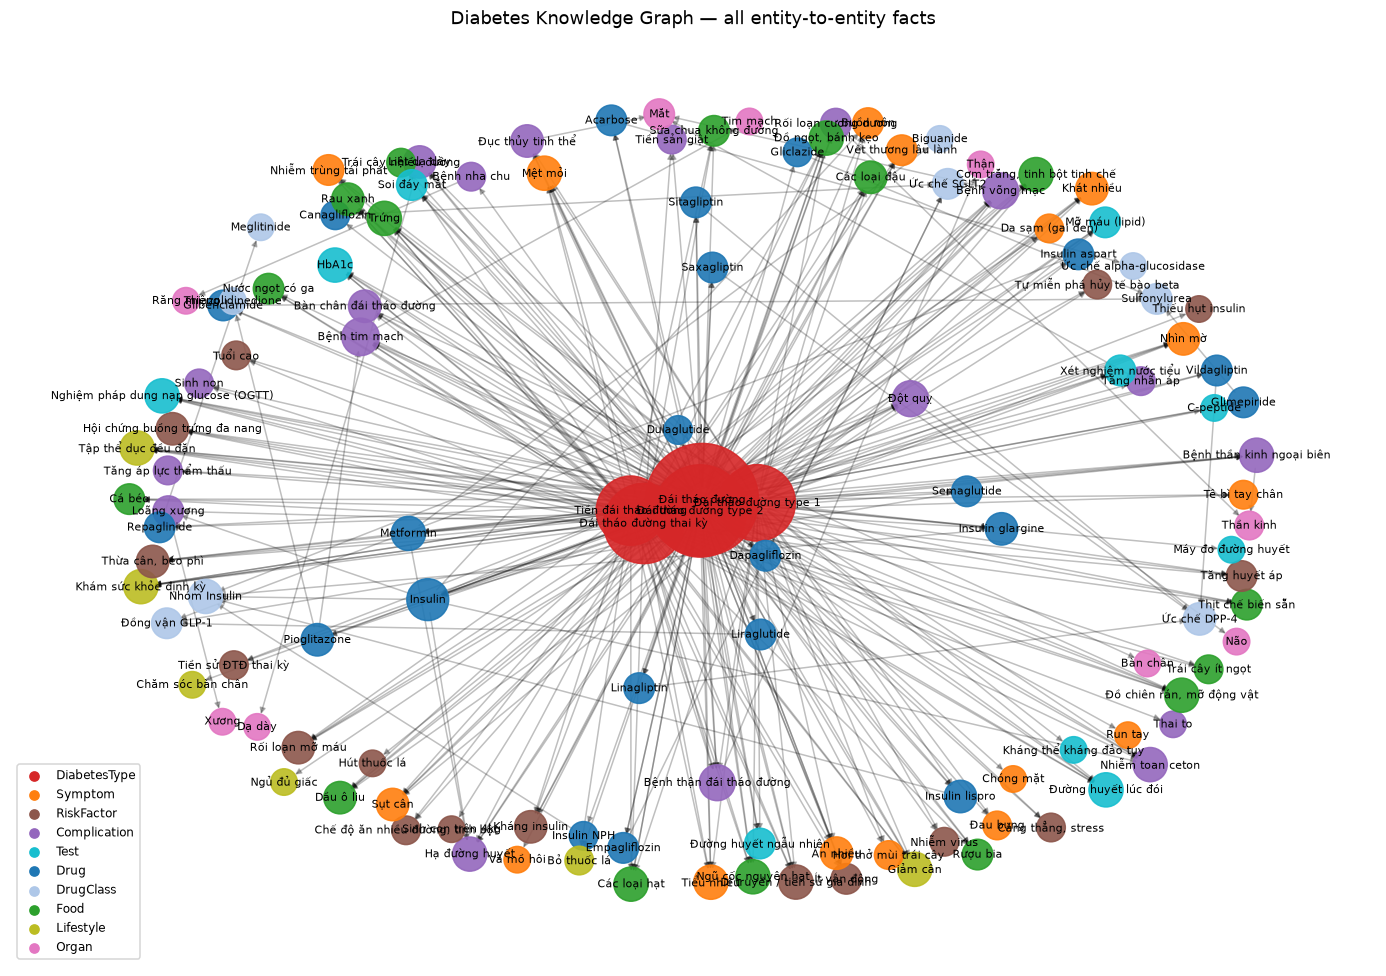

In [30]:
from visualize import build_graph, COLORS
%matplotlib inline
G = build_graph()
print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges, density = {nx.density(G):.3f}")

def draw(H, title, edge_labels=False, k=0.9, size=(16, 11)):
    plt.figure(figsize=size)
    pos = nx.spring_layout(H, k=k, seed=7)
    nx.draw_networkx_edges(H, pos, alpha=0.25, arrowsize=8)
    nx.draw_networkx_nodes(H, pos, node_color=[COLORS.get(H.nodes[n].get("type"), "#999") for n in H],
                           node_size=[250 + 50 * H.degree(n) for n in H], alpha=0.9)
    nx.draw_networkx_labels(H, pos, font_size=7)
    if edge_labels:
        nx.draw_networkx_edge_labels(H, pos, nx.get_edge_attributes(H, "relation"), font_size=6)
    for lab, c in COLORS.items(): plt.scatter([], [], c=c, label=lab)
    plt.legend(loc="lower left", fontsize=8); plt.title(title); plt.axis("off"); plt.show()

draw(G, "Diabetes Knowledge Graph — all entity-to-entity facts")

### 8.2 Looking at one part at a time

The full picture shows the overall structure but is hard to read in detail. Two smaller pictures are clearer:

- **Gestational diabetes and its direct neighbours.** Only the arrows that touch the gestational-diabetes dot are drawn, with their relation names. You can read off everything the graph knows about it: its symptoms, its pregnancy-specific complications, its tests, the foods discussed for it.
- **Type 2 treatment.** The drugs used for type 2, their classes and their side effects. Drawing the class arrows makes the drug families appear as small clusters (several DPP-4 inhibitors around their class dot, several SGLT2 inhibitors around theirs), which is exactly how doctors think of these drugs.

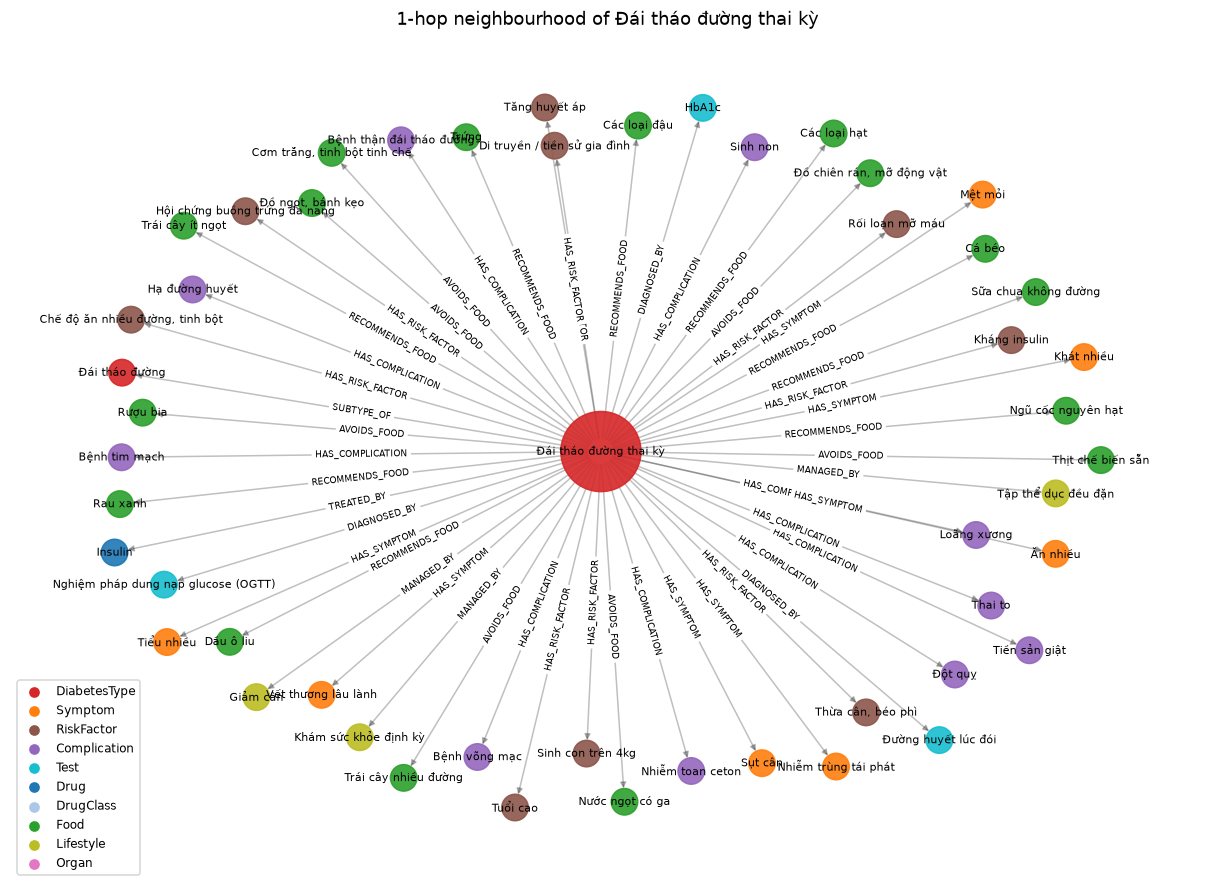

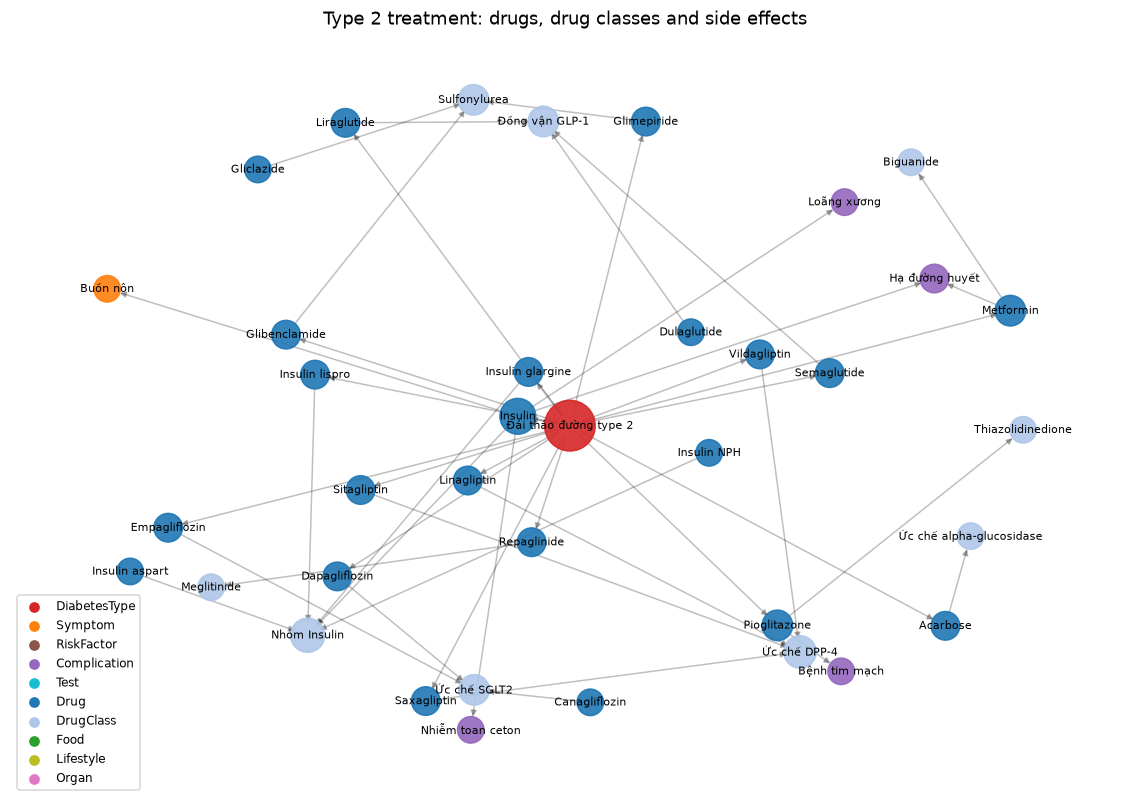

In [31]:
def one_hop(G, center):
    H = nx.DiGraph(); H.add_node(center, **G.nodes[center])
    for u, v, d in [*G.out_edges(center, data=True), *G.in_edges(center, data=True)]:
        H.add_node(u, **G.nodes[u]); H.add_node(v, **G.nodes[v]); H.add_edge(u, v, **d)
    return H

draw(one_hop(G, "Đái tháo đường thai kỳ"), "1-hop neighbourhood of Đái tháo đường thai kỳ", edge_labels=True, k=1.4, size=(14, 10))

drug_edges = [(u, v, d) for u, v, d in G.edges(data=True)
              if (u == "Đái tháo đường type 2" and d["relation"] == "TREATED_BY") or d["relation"] in ("BELONGS_TO_CLASS", "HAS_SIDE_EFFECT")]
D = nx.DiGraph()
for u, v, d in drug_edges:
    D.add_node(u, **G.nodes[u]); D.add_node(v, **G.nodes[v]); D.add_edge(u, v, **d)
draw(D, "Type 2 treatment: drugs, drug classes and side effects", k=0.8, size=(13, 9))

### 8.3 Which entities are the most important?

"Important" can mean different things for a node in a graph, and two common ways to measure it give quite different answers here. Understanding why is a good way to understand the graph itself.

**Degree** is the simplest measure: the number of arrows that touch a node. It answers "how many facts involve this entity?". It only looks at the node's own arrows, not at what they lead to.

**PageRank** is the method Google originally used to rank web pages. Its idea is that a node is important if *important* nodes point to it — not just many nodes. It is easiest to understand as a walk: imagine a person who starts on a random node, and at each step either follows one of the outgoing arrows of the node they are on (chosen at random), or, now and then, gets bored and jumps to a completely random node. After walking for a very long time, PageRank is the share of time they spent on each node. Nodes that many paths lead into are visited often and get a high score.

**What happens in our graph.** Look at the direction of our arrows: they all point *away* from the diabetes types — type → drug → drug class, type → complication → organ. A walker who follows the arrows keeps drifting down these chains and arrives at the ends: the drug classes and the organs. Those nodes have no outgoing arrows, so the walker gets stuck there until the next random jump. The result is that directed PageRank puts "Nhóm Insulin", "Ức chế DPP-4" and "Mắt" (eye) at the top. They are not what the articles are mainly about; they are simply where many paths end.

The direction of our arrows is our own choice when we designed the relations: "type 2 HAS_SYMPTOM thirst" could just as well have been written "thirst SYMPTOM_OF type 2", pointing the other way. A measure whose answer flips when you rename a relation is not measuring what we want here. So we also compute PageRank **ignoring the direction**, as if every arrow could be walked both ways. Then a node is important if it is well connected to other well-connected nodes. That ranking is the one that makes sense for this graph: the diabetes types first, then insulin, cardiovascular disease, stroke, kidney disease, retinopathy and Metformin — the treatments and complications that tie the whole graph together.

The lesson is that a graph measure always answers a specific question, and you have to check that it is the question you want to ask.

Top by directed PageRank (dead ends of the chains):


,type,degree,PR directed,PR undirected
Nhóm Insulin,DrugClass,5,0.0290,0.0077
Ức chế DPP-4,DrugClass,4,0.0277,0.0067
Mắt,Organ,3,0.0226,0.0053
Ức chế SGLT2,DrugClass,3,0.0222,0.0058
Sulfonylurea,DrugClass,3,0.0222,0.0058
Đồng vận GLP-1,DrugClass,3,0.0222,0.0058
Thần kinh,Organ,2,0.0171,0.0039
Tim mạch,Organ,1,0.0142,0.0024


Top by undirected PageRank (central entities):


,type,degree,PR directed,PR undirected
Đái tháo đường,DiabetesType,104,0.0066,0.1456
Đái tháo đường type 2,DiabetesType,68,0.0062,0.0881
Đái tháo đường thai kỳ,DiabetesType,50,0.0062,0.0645
Đái tháo đường type 1,DiabetesType,45,0.0062,0.0572
Tiền đái tháo đường,DiabetesType,36,0.0062,0.0449
Insulin,Drug,10,0.0067,0.0133
Bệnh tim mạch,Complication,7,0.0094,0.0103
Đột quỵ,Complication,6,0.0067,0.0088
Bệnh thận đái tháo đường,Complication,6,0.0067,0.0088
Bệnh võng mạc,Complication,6,0.0067,0.0082


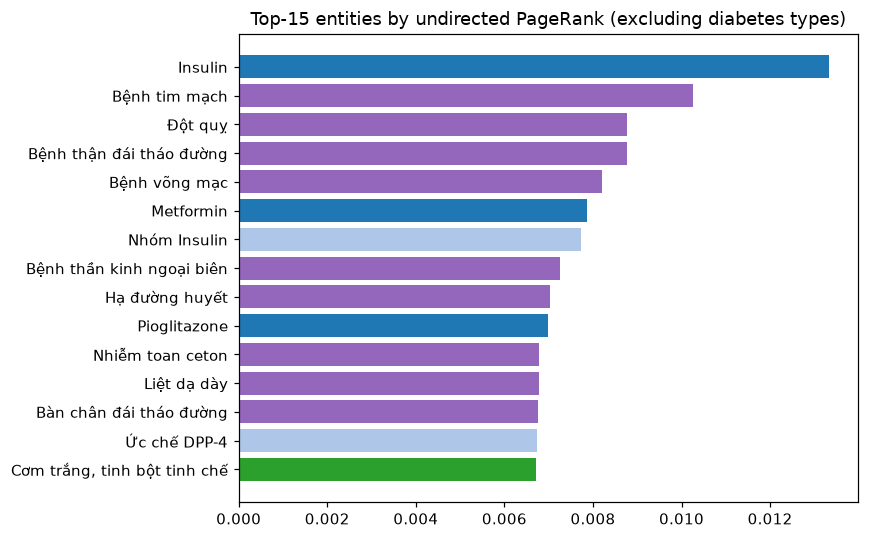

In [32]:
pr_dir = nx.pagerank(G, alpha=0.85)
pr_und = nx.pagerank(G.to_undirected(), alpha=0.85)
cent = pd.DataFrame({"type": nx.get_node_attributes(G, "type"), "degree": dict(G.degree()),
                     "PR directed": pr_dir, "PR undirected": pr_und})
fmt = {"PR directed": "{:.4f}", "PR undirected": "{:.4f}"}
print("Top by directed PageRank (dead ends of the chains):")
display(cent.sort_values("PR directed", ascending=False).head(8).style.format(fmt))
print("Top by undirected PageRank (central entities):")
display(cent.sort_values("PR undirected", ascending=False).head(12).style.format(fmt))

top = cent[cent.type != "DiabetesType"].sort_values("PR undirected", ascending=False).head(15)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["PR undirected"], color=[COLORS[t] for t in top.type])
plt.title("Top-15 entities by undirected PageRank (excluding diabetes types)"); plt.tight_layout(); plt.show()

### 8.4 What Vinmec writes about most

A third view of importance does not use the facts at all. It counts, for each entity, in how many of the 1,096 articles it is mentioned anywhere (the MENTIONS links). This measures what the website *talks about*, which is different from how connected an entity is in the graph of facts. An entity can be mentioned in many articles in passing, for example while explaining how blood sugar works, while taking part in only a few extracted facts; comparing this chart with the PageRank chart shows which topics are talked about a lot but rarely stated as a fact under a proper heading.

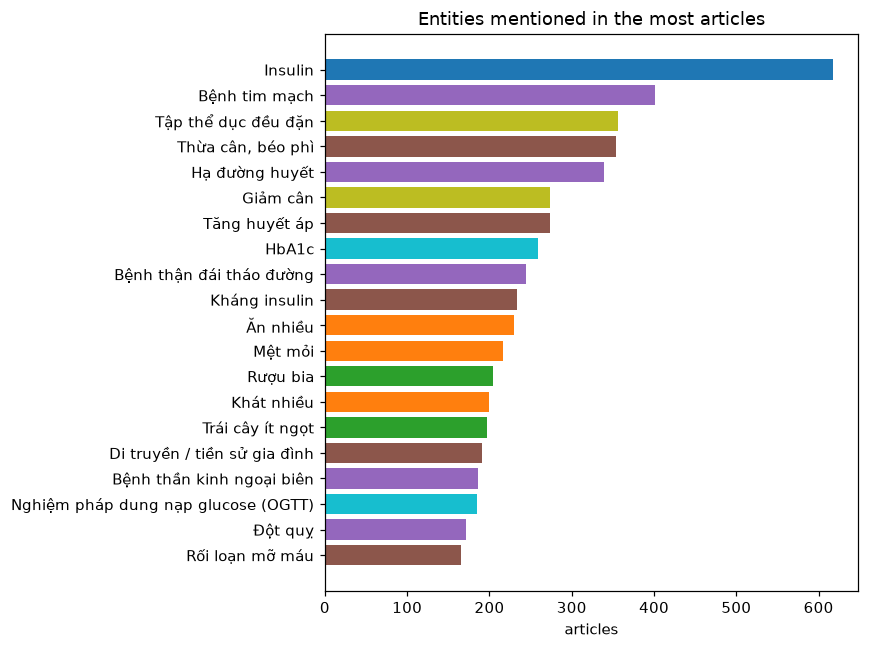

In [33]:
mc = cy('''
MATCH (a:Article)-[:MENTIONS]->(e:Entity)
RETURN [l IN labels(e) WHERE l <> 'Entity'][0] AS type, e.name AS entity, count(a) AS articles
ORDER BY articles DESC LIMIT 20''')[::-1]
plt.figure(figsize=(8, 6))
plt.barh(mc.entity, mc.articles, color=[COLORS.get(t, "#999") for t in mc.type])
plt.title("Entities mentioned in the most articles"); plt.xlabel("articles"); plt.tight_layout(); plt.show()

## 9. How good is the graph?

Every automatic extractor makes mistakes. The important question is not whether there are mistakes, but how many, and of what kind. Without measuring this, any claim about the graph ("the graph says insulin causes X") cannot be trusted.

### What we measured

We measured **precision**: of the facts the graph contains, what share are correct? The method:

1. pick 50 of the extracted facts at random (with a fixed random seed, so anyone re-running `kg/evaluate.py` gets the same 50);
2. for each fact, show a sentence from a section that the extractor actually used, and the article title;
3. judge each fact by reading **all** of its supporting articles, not only the first sentence shown.

"Correct" here means that the Vinmec articles really state this fact for this type of diabetes. It does not mean that a doctor checked the fact against current clinical guidelines; that would be a different and much more expensive check.

Why random facts, and why only 50? Random, because if we chose the facts ourselves we would unconsciously pick easy ones and the result would look better than it is. Fifty, because each fact must be checked by reading several articles, which takes time; 50 is enough to see the main error patterns and to give a reasonable estimate.

### Result

**48 of the 50 facts are correct, which is 96 %.** The two errors have the same cause: a fact about a *complication* was attached to diabetes itself.

| wrong fact | what the articles really said |
|---|---|
| diabetes HAS_RISK_FACTOR high cholesterol | high cholesterol is listed as a risk factor of the *kidney* and *eye* complications ("Những ai dễ bị bệnh thận đái tháo đường?") |
| diabetes HAS_SYMPTOM abdominal pain | abdominal pain is a symptom of *ketoacidosis* and of nerve damage in the gut |

How precise is "96 %"? With only 50 facts, the true value for the whole graph could be somewhat higher or lower: if we had picked a different 50 by chance, we might have found one error or four. The standard statistical calculation for this situation says that, given 48 correct out of 50, the true precision of the whole graph is very likely between about 87 % and 99 %. In other words: the graph is good, but "96 %" should be read as "roughly 9 out of 10 or better", not as an exact number.

In [34]:
sample = pd.read_csv(ROOT / "evaluation" / "manual_audit.csv")
n, k = len(sample), int(sample.correct.sum())
z = 1.96; p = k / n
centre = (p + z*z/(2*n)) / (1 + z*z/n); half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
print(f"precision = {k}/{n} = {p:.2f}   likely range for the whole graph: {centre-half:.2f} to {centre+half:.2f}\n")
display(sample.groupby("relation").correct.agg(["count", "sum"]).rename(columns={"count": "sampled", "sum": "correct"}))
display(sample[sample.correct == 0][["subject", "relation", "object", "error_type"]])

precision = 48/50 = 0.96   likely range for the whole graph: 0.87 to 0.99



,sampled,correct
relation,,
AVOIDS_FOOD,7,7
DIAGNOSED_BY,6,6
HAS_COMPLICATION,7,7
HAS_RISK_FACTOR,11,10
HAS_SYMPTOM,7,6
MANAGED_BY,2,2
RECOMMENDS_FOOD,3,3
TREATED_BY,7,7


,subject,relation,object,error_type
3,Đái tháo đường,HAS_RISK_FACTOR,Rối loạn mỡ máu,risk factor of a complication attached to the disease
30,Đái tháo đường,HAS_SYMPTOM,Đau bụng,symptom of a complication (DKA / neuropathy) attached to the disease


### 9.1 Fixing the errors, and what it cost

The two errors led directly to the stricter heading rule explained in 3.3: a symptom or risk factor section must be about diabetes itself, not about a complication or another disease. After the change the graph went from 345 to 339 facts. Looking at the six removed facts is instructive:

| removed fact | was the removal right? |
|---|---|
| type 1 HAS_SYMPTOM numb hands and feet | ✅ yes: that is the nerve-damage complication, not a symptom of type 1 |
| type 2 HAS_SYMPTOM sweating | ✅ yes: that is a symptom of low blood sugar |
| prediabetes HAS_RISK_FACTOR older age | ❌ no, a true fact was lost |
| prediabetes HAS_RISK_FACTOR high blood pressure | ❌ no, a true fact was lost |
| diabetes HAS_RISK_FACTOR long-term corticosteroid use | ❌ no, a true fact was lost |
| type 2 HAS_RISK_FACTOR smoking | ❌ no, a true fact was lost |

The four true facts were lost because each had exactly one good supporting article plus one weak one. The stricter rule removed the weak one, the support fell to 1, and the minimum of 2 removed the fact.

And the two original errors? They stayed in the graph, but with much less support (16 → 3 pages and 18 → 6 pages). Reading the remaining pages showed that they *do* state these facts under genuine diabetes headings, for example "Nguyên nhân và yếu tố nguy cơ gây bệnh tiểu đường: … Rối loạn mỡ máu". By our definition of "correct" (the articles state it), they are now supported properly.

This is a trade-off that every extraction system faces. Strict rules produce fewer wrong facts but miss more true ones; loose rules find more true facts but let in more wrong ones. There is no setting that is best for every use. That is why the support number is kept on every fact instead of being used only once as a filter. Each user of the graph can choose their own level of caution: a chatbot giving health information might only use facts with support 3 or more, while someone exploring the data can see everything.

The cell below shows how many extracted facts remain at each level of required support.

In [35]:
for th in [1, 2, 3, 5, 10]:
    cnt = cy("MATCH ()-[r]->() WHERE r.source = 'vinmec' AND r.support >= $t RETURN count(r) AS n", t=th).n[0]
    print(f"facts with support ≥ {th:2d}: {cnt}")

facts with support ≥  1: 301
facts with support ≥  2: 295
facts with support ≥  3: 252
facts with support ≥  5: 161
facts with support ≥ 10: 70


## 10. What this graph cannot do

Following the lecture's list of the ways a knowledge graph can fail:

- **Missing entities.** The vocabulary is fixed: 106 entities written in 320 different ways. Anything that is not in it can never be found, however many articles discuss it — a newer insulin brand, a rarer complication, a traditional remedy. We measured how many extracted facts are correct (precision), but not how many true facts in the articles were missed (recall), so we do not know how much is missing.
- **Wrong relationships.** About 4 % of the sampled facts were wrong, mostly facts about a complication attached to the disease. Section headings are a strong signal of meaning, but not a perfect one.
- **Ambiguous aliases.** The whole-word rule stops matches inside longer words, but not short aliases that are complete words with another meaning: the fruit "táo" also matches "táo bón" (constipation). The section rule makes this rare but does not remove it.
- **Cause mistaken for side effect.** "Insulin HAS_SIDE_EFFECT ketoacidosis" survived the filter in 3.8. Ketoacidosis comes from a *lack* of insulin, expressed in a way the "thiếu / không đủ" check does not catch.
- **Coarse subjects.** The type of diabetes is taken only from the title, so many facts that are really about type 2 sit on the general diabetes node.
- **Fixed food advice.** Whether a food is recommended or to avoid is decided by the food, not read from the article, so advice like "fruit is fine in moderate amounts" is lost.
- **Merged or split meanings.** Aliases deliberately merge near-synonyms ("tê bì", "dị cảm", "kiến bò" all become numb hands and feet), and sometimes merge things a doctor would keep apart.
- **One source, of different ages.** All facts come from one hospital's website, and an article from 2019 counts the same as one from 2025. "Correct" means "stated by Vinmec", not "checked against current guidelines".
- **Hand-added facts.** Drug classes, affected organs and diagnostic thresholds were added by hand. They are clearly labelled `curated`, but they were not learned from the articles.
- **Not medical advice.** The graph summarises public health articles. The symptom checker shows which types are associated with symptoms in those articles; it does not diagnose anyone.

In [36]:
driver.close()